# 03 — Coyuntura Macroeconómica y Modelación Predictiva del IMACEC (Chile)

Este cuaderno constituye el **estudio empírico principal del proyecto**. A partir de las **17 series macroeconómicas** almacenadas en `data/coyuntura.db` (`2010-01-01` a `2026-08-31`), desarrollamos el flujo completo de investigación:

1. **Extracción Analítica SQL:** Consolidación mensual desde SQLite mediante `JOIN`, `GROUP BY` y funciones de ventana (`LAG` y `AVG OVER`).
2. **Diagnóstico de Coyuntura:** Caracterización visual de la trayectoria en nivel, dinámica interanual y postura monetaria/sectorial.
3. **Estacionariedad y Rezagos:** Transformaciones homogéneas, contraste *Augmented Dickey-Fuller* (ADF) en muestra de entrenamiento y análisis de capacidad anticipatoria ($k \ge 1$).
4. **Competencia de Modelos Out-of-Sample (48 meses):** Evaluación sin sesgo de anticipación (*zero look-ahead bias*) comparando modelos univariados (`AR(p*)`, `ARIMA`, `SARIMA`), regularizados (`Ridge`, `Elastic Net`) y de árboles (`CART`, `Random Forest`) frente a tres *benchmarks* formales.

## 1. Configuración del Entorno y Extracción Consolidada desde SQLite

**Síntesis:** Importamos las librerías científicas del proyecto, conectamos con `data/coyuntura.db` a través de `src/carga_db.py` y ejecutamos una consulta SQL única que filtra la ventana oficial del estudio (`2010-01-01` a `2026-08-31`), colapsa las series diarias a promedios mensuales (`GROUP BY`), calcula las variaciones interanuales a 12 meses (`LAG`) y los promedios móviles (`AVG OVER`), organizando los resultados en matrices mensuales sincronizadas.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sqlalchemy import text
from statsmodels.tsa.stattools import adfuller

# 1. Silenciar advertencias numéricas de optimización y configurar estilo gráfico
warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")

# 2. Detectar raíz del repositorio y habilitar importaciones desde `src/`
raiz_repo = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
ruta_src = raiz_repo / "src"
if str(ruta_src) not in sys.path:
    sys.path.insert(0, str(ruta_src))

import config
import carga_db

# 3. Parámetros temporales oficiales del estudio (reproducibilidad estricta)
FECHA_INICIO = "2010-01-01"
FECHA_FIN_MES = "2026-08-01"
FECHA_FIN_SQL = "2026-08-31"     # Incluye todos los días hábiles de agosto 2026
FECHA_FIN_TRAIN = "2022-08-01"   # Corte estricto de entrenamiento (48 meses reservados para OOS)

LIMITE_X_MIN = pd.Timestamp(FECHA_INICIO)
LIMITE_X_MAX = pd.Timestamp(FECHA_FIN_MES)
ID_OBJETIVO = config.ID_OBJETIVO  # "F032.IMC.IND.Z.Z.EP18.Z.Z.0.M"

# 4. Consulta SQL analítica: GROUP BY (diario->mensual) + LAG 12M + AVG OVER 12M + JOIN
engine = carga_db.obtener_engine()

query_consolidada = text("""
    WITH mensual AS (
        SELECT
            o.id_serie,
            strftime('%Y-%m', o.fecha) AS mes,
            AVG(o.valor) AS valor_mensual
        FROM observaciones AS o
        WHERE o.fecha BETWEEN :inicio AND :fin
        GROUP BY o.id_serie, mes
    ),
    con_variacion AS (
        SELECT
            m.id_serie,
            m.mes,
            m.valor_mensual,
            100.0 * (m.valor_mensual / NULLIF(LAG(m.valor_mensual, 12) OVER (
                PARTITION BY m.id_serie ORDER BY m.mes
            ), 0) - 1.0) AS var_12m_pct,
            AVG(m.valor_mensual) OVER (
                PARTITION BY m.id_serie ORDER BY m.mes
                ROWS BETWEEN 11 PRECEDING AND CURRENT ROW
            ) AS pm_12m
        FROM mensual AS m
    )
    SELECT
        v.id_serie,
        s.nombre,
        t.tema,
        s.unidad,
        v.mes || '-01' AS fecha,
        v.valor_mensual,
        v.var_12m_pct,
        v.pm_12m
    FROM con_variacion AS v
    JOIN series AS s ON s.id_serie = v.id_serie
    JOIN temas AS t ON t.id_tema = s.id_tema
    ORDER BY v.id_serie, v.mes;
""")

with engine.connect() as conn:
    df_sql = pd.read_sql(
        query_consolidada,
        conn,
        params={"inicio": FECHA_INICIO, "fin": FECHA_FIN_SQL},
        parse_dates=["fecha"],
    )

# 5. Reestructurar en paneles mensuales alineados (200 meses: 2010-01 a 2026-08)
rango_mensual = pd.date_range(FECHA_INICIO, FECHA_FIN_MES, freq="MS")
df_nivel = df_sql.pivot(index="fecha", columns="id_serie", values="valor_mensual").reindex(rango_mensual)
df_var12m = df_sql.pivot(index="fecha", columns="id_serie", values="var_12m_pct").reindex(rango_mensual)
df_pm12m = df_sql.pivot(index="fecha", columns="id_serie", values="pm_12m").reindex(rango_mensual)

mapa_nombres = df_sql[["id_serie", "nombre"]].drop_duplicates().set_index("id_serie")["nombre"].to_dict()

print(f"Series activas cargadas desde SQLite : {df_nivel.shape[1]}")
print(f"Ventana temporal consolidada        : {df_nivel.index.min().strftime('%Y-%m-%d')} a {df_nivel.index.max().strftime('%Y-%m-%d')} ({len(df_nivel)} meses)")

Series activas cargadas desde SQLite : 17
Ventana temporal consolidada        : 2010-01-01 a 2026-08-01 (200 meses)


## 2. Diagnóstico Visual de Coyuntura Macroeconómica (2010–2026)

**Síntesis:** Construimos una lámina descriptiva de tres paneles sincronizados para examinar la evolución estructural y cíclica de la economía chilena:
1. **Nivel y Tendencia:** Índice IMACEC empalmado (`2018 = 100`) junto a su promedio móvil de 12 meses.
2. **Ciclo de Crecimiento:** Variación interanual (%) del IMACEC contrastada contra el umbral de expansión (`0%`) y su promedio histórico (`2011–2026`).
3. **Tracción Sectorial y Política Monetaria:** Desempeño interanual de los tres sectores líderes (*Servicios*, *Comercio* y *Minería*) frente a la trayectoria de la **Tasa de Política Monetaria (TPM)**.

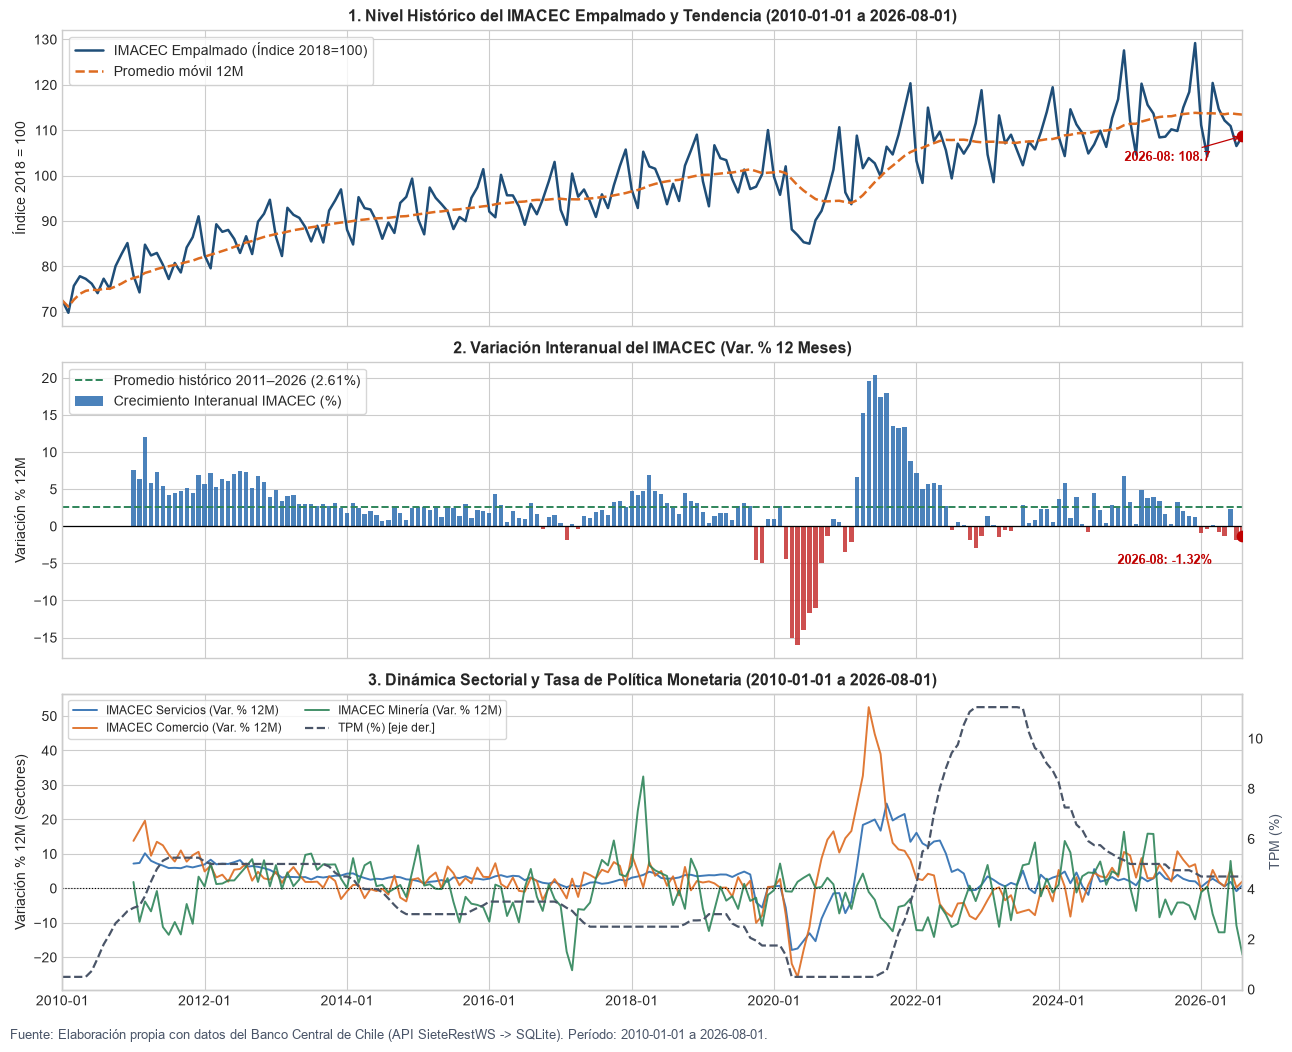

In [2]:
# 1. Extraer series principales del IMACEC y calcular estadísticos de referencia
imacec_nivel = df_nivel[ID_OBJETIVO]
imacec_pm12 = df_pm12m[ID_OBJETIVO]
imacec_var = df_var12m[ID_OBJETIVO]

media_hist = float(imacec_var.dropna().mean())
ultimo_nivel = float(imacec_nivel.loc[LIMITE_X_MAX])
ultima_var = float(imacec_var.loc[LIMITE_X_MAX])

fig, axes = plt.subplots(3, 1, figsize=(13, 10.5), sharex=True)

# 2. Panel 1: Nivel del IMACEC y promedio móvil 12M
axes[0].plot(imacec_nivel.index, imacec_nivel, color="#1f4e78", lw=1.8, label="IMACEC Empalmado (Índice 2018=100)")
axes[0].plot(imacec_pm12.index, imacec_pm12, color="#dd6b20", lw=1.8, linestyle="--", label="Promedio móvil 12M")
axes[0].scatter(LIMITE_X_MAX, ultimo_nivel, color="#c00000", s=55, zorder=5)
axes[0].annotate(
    f"2026-08: {ultimo_nivel:.1f}",
    xy=(LIMITE_X_MAX, ultimo_nivel),
    xytext=(-85, -18),
    textcoords="offset points",
    fontsize=9, fontweight="bold", color="#c00000",
    arrowprops=dict(arrowstyle="->", color="#c00000", lw=0.9),
)
axes[0].set_title("1. Nivel Histórico del IMACEC Empalmado y Tendencia (2010-01-01 a 2026-08-01)", fontsize=11.5, fontweight="bold")
axes[0].set_ylabel("Índice 2018 = 100")
axes[0].legend(loc="upper left", frameon=True)

# 3. Panel 2: Variación interanual (%) del IMACEC
var_valida = imacec_var.dropna()
colores_barras = ["#2b6cb0" if v >= 0 else "#c53030" for v in var_valida]
axes[1].bar(var_valida.index, var_valida, width=22, color=colores_barras, alpha=0.85, label="Crecimiento Interanual IMACEC (%)")
axes[1].axhline(0, color="black", lw=0.9)
axes[1].axhline(media_hist, color="#2f855a", linestyle="--", lw=1.4, label=f"Promedio histórico 2011–2026 ({media_hist:.2f}%)")
axes[1].scatter(LIMITE_X_MAX, ultima_var, color="#c00000", s=55, zorder=5)
axes[1].annotate(
    f"2026-08: {ultima_var:+.2f}%",
    xy=(LIMITE_X_MAX, ultima_var),
    xytext=(-90, 14 if ultima_var >= 0 else -20),
    textcoords="offset points",
    fontsize=9, fontweight="bold", color="#c00000",
)
axes[1].set_title("2. Variación Interanual del IMACEC (Var. % 12 Meses)", fontsize=11.5, fontweight="bold")
axes[1].set_ylabel("Variación % 12M")
axes[1].legend(loc="upper left", frameon=True)

# 4. Panel 3: Principales sectores (Servicios, Comercio, Minería) y TPM en eje secundario
sectores_plot = {
    "F032.IMC.IND.Z.Z.EP18.SERV.Z.0.M": ("IMACEC Servicios (Var. % 12M)", "#2b6cb0"),
    "F032.IMC.IND.Z.Z.EP18.COM.Z.0.M": ("IMACEC Comercio (Var. % 12M)", "#dd6b20"),
    "F032.IMC.IND.Z.Z.EP18.03.Z.0.M": ("IMACEC Minería (Var. % 12M)", "#2f855a"),
}
for cod, (etiqueta, color) in sectores_plot.items():
    axes[2].plot(df_var12m.index, df_var12m[cod], lw=1.4, label=etiqueta, color=color, alpha=0.9)

axes[2].axhline(0, color="black", lw=0.8, linestyle=":")
axes[2].set_ylabel("Variación % 12M (Sectores)")
axes[2].set_title("3. Dinámica Sectorial y Tasa de Política Monetaria (2010-01-01 a 2026-08-01)", fontsize=11.5, fontweight="bold")

ax2_twin = axes[2].twinx()
tpm_serie = df_nivel["F022.TPM.TIN.D001.NO.Z.D"]
ax2_twin.plot(tpm_serie.index, tpm_serie, color="#4a5568", linestyle="--", lw=1.6, label="TPM (%) [eje der.]")
ax2_twin.set_ylabel("TPM (%)", color="#4a5568")
ax2_twin.grid(False)

# 5. Homologar límites y formato de eje temporal en los 3 paneles
for ax in axes:
    ax.set_xlim(LIMITE_X_MIN, LIMITE_X_MAX)
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))

h1, l1 = axes[2].get_legend_handles_labels()
h2, l2 = ax2_twin.get_legend_handles_labels()
axes[2].legend(h1 + h2, l1 + l2, loc="upper left", fontsize=8.5, ncol=2, frameon=True)

fig.text(
    0.01, 0.005,
    "Fuente: Elaboración propia con datos del Banco Central de Chile (API SieteRestWS -> SQLite). Período: 2010-01-01 a 2026-08-01.",
    fontsize=9, color="#4a5568",
)
plt.tight_layout(rect=[0, 0.02, 1, 1])
plt.show()

### Interpretación del Diagnóstico Visual de Coyuntura Macroeconómica (2010–2026)

El análisis gráfico conjunto del IMACEC en nivel, su tasa de crecimiento interanual, el desempeño sectorial y la postura de política monetaria evidencia tres dinámicas estructurales clave para la especificación econométrica:

#### 1. Nivel Histórico y Tendencia del IMACEC (Panel Superior)
* **Tendencia y estacionalidad marcada:** El índice IMACEC empalmado (`2018 = 100`) exhibe una trayectoria ascendente de largo plazo —desde niveles cercanos a `72` puntos en 2010 hasta máximos estacionales sobre `125` puntos en los últimos años—, superpuesta a un patrón estacional intra-anual altamente regular (picos en el cuarto trimestre y caídas en febrero).
* **Quiebre pandémico y cambio de nivel:** Se observan tres fases claras: crecimiento sostenido entre 2010 y 2019; el choque exógeno de 2020 (caída abrupta hacia ~`85` puntos) seguido de un rebote en «V» en 2021; y una meseta de ajuste en 2022–2023 previa a una nueva expansión moderada en 2024–2025.
* **Debilidad en el margen (`2026-08`):** Al cierre de agosto de 2026, el índice registra **108.7 puntos**, situándose por debajo de su promedio móvil de 12 meses (~`113.5` puntos), señal de pérdida de dinamismo reciente.
* **Implicancia econométrica:** La presencia simultánea de tendencia y estacionalidad confirma que la serie en nivel es no estacionaria, justificando su transformación a variación interanual de 12 meses.

#### 2. Ciclo de Crecimiento Interanual (Panel Central)
* **Reversión a la media y volatilidad:** La variación porcentual a 12 meses fluctúa en torno a un **promedio histórico de 2.61% (2011–2026)**, con episodios de alta volatilidad concentrados en el período 2020–2021.
* **Regímenes cíclicos:**
  * *2011–2013:* Expansión vigorosa (`4%` a `12%`) impulsada por el ciclo favorable del cobre.
  * *2014–2019:* Moderación del crecimiento hacia un rango de `1%`–`3%`, interrumpida por un repunte transitorio en 2018 y una contracción cercana a `-4.5%` a fines de 2019.
  * *2020–2023:* Contracción histórica (`-15%` en 2020), rebote extraordinario por efecto base y liquidez (`+20%` en 2021) y ajuste contractivo leve en 2023 (`-1%` a `-3%`).
  * *2024–2026:* Recuperación moderada durante 2024–2025 (`1%`–`5%`), seguida de una desaceleración sostenida en 2026 que lleva el crecimiento a **-1.32% en `2026-08`** (`3.93` puntos porcentuales por debajo de su media histórica).

#### 3. Dinámica Sectorial y Transmisión de la Política Monetaria (Panel Inferior)
* **Alta sensibilidad de la demanda interna (*Comercio* y *Servicios*):** Ambos sectores lideran los puntos de giro del ciclo agregado y responden con rezago a las condiciones financieras. Durante el estímulo de 2021, *Comercio* superó el `+50%` interanual y *Servicios* bordeó el `+20%`, contrayéndose posteriormente en 2022–2023 tras el endurecimiento monetario. Hacia agosto de 2026, el retroceso interanual de *Servicios* explica gran parte de la caída del IMACEC total.
* **Comportamiento idiosincrático de *Minería*:** A diferencia de los sectores ligados al gasto interno, *Minería* presenta choques de oferta propios y alta variabilidad de corto plazo (como la caída cercana a `-23%` a inicios de 2017 y el repunte superior a `+30%` en 2018), manteniéndose desacoplada del ciclo de tasas de interés.
* **Rol contracíclico de la TPM:** Tras permanecer en su mínimo técnico de **0.5%** entre 2020 y mediados de 2021, la Tasa de Política Monetaria escaló hasta **11.25%** entre fines de 2022 y mediados de 2023 para contener la inflación, iniciando luego una trayectoria de normalización gradual hacia niveles en torno a **4.0%–4.25%** en 2026.

## 3. Transformaciones Económicas Homogéneas y Test de Estacionariedad (ADF)

**Síntesis:** Estandarizamos las 17 series macroeconómicas bajo un criterio económico coherente con la ventana interanual de 12 meses:
* **Índices, precios y flujos en USD (14 series):** Se expresan en **variación porcentual a 12 meses (`Var. % 12M`)**, removiendo simultáneamente tendencia estocástica y estacionalidad.
* **Variables ya expresadas en tasas o porcentajes (3 series: TPM, Desocupación y Expectativa de Inflación):** Se expresan como **diferencia interanual en puntos porcentuales (`Cambio 12M en pp`)** para evitar explosiones numéricas cuando las tasas parten cercanas a cero.

Posteriormente aplicamos el test **Augmented Dickey-Fuller (ADF)** exclusivamente sobre la muestra de entrenamiento (`hasta 2022-08-01`) para verificar estacionariedad sin contaminar con datos de prueba.

In [3]:
# 1. Clasificación de las 17 series según su unidad económica original
ID_TPM = "F022.TPM.TIN.D001.NO.Z.D"

SERIES_SECTORIALES = [
    "F032.IMC.IND.Z.Z.EP18.03.Z.0.M",    # Minería
    "F032.IMC.IND.Z.Z.EP18.04.Z.0.M",    # Industria
    "F032.IMC.IND.Z.Z.EP18.RB.Z.0.M",    # Resto bienes
    "F032.IMC.IND.Z.Z.EP18.COM.Z.0.M",   # Comercio
    "F032.IMC.IND.Z.Z.EP18.SERV.Z.0.M",  # Servicios
    "F032.IMC.IND.Z.Z.EP18.IMP.Z.0.M",   # Impuestos
]

SERIES_MACRO_PORCENTUAL = [
    "F019.PPB.PRE.40.M",                    # Precio cobre
    "F073.TCO.PRE.Z.D",                     # Tipo cambio observado
    "F068.B1.FLU.A1.0.C.N.Z.Z.Z.Z.6.0.M",   # Exportaciones cobre
    "F068.B1.FLU.A8.0.C.N.Z.Z.Z.Z.6.0.M",   # Exportaciones litio
    "F068.B1.FLU.B.0.C.N.Z.Z.Z.Z.6.0.M",    # Exportaciones agropecuarias
    "F068.B1.FLU.Z.0.M.N.A.Z.Z.Z.6.0.M",    # Importaciones consumo
    "F089.TCN.PRE.14.M",                    # Expectativa tipo cambio 11m
]

SERIES_TASAS_PP = [
    "F049.DES.TAS.INE9.10.M",   # Tasa desocupación (%)
    "F089.IPC.V12.14.M",        # Expectativa inflación 11m (%)
    ID_TPM,                     # Tasa de Política Monetaria (%)
]

# 2. Construir panel transformado homogéneo
df_trans = pd.DataFrame(index=rango_mensual)
df_trans[ID_OBJETIVO] = df_var12m[ID_OBJETIVO]

for cod in SERIES_SECTORIALES + SERIES_MACRO_PORCENTUAL:
    df_trans[cod] = df_var12m[cod]

for cod in SERIES_TASAS_PP:
    df_trans[cod] = df_nivel[cod] - df_nivel[cod].shift(12)

# 3. Ejecutar contraste Augmented Dickey-Fuller (ADF) SOLO en entrenamiento (hasta 2022-08-01)
df_trans_train = df_trans.loc[:FECHA_FIN_TRAIN]

resultados_adf = []
for cod in [ID_OBJETIVO] + SERIES_SECTORIALES + SERIES_MACRO_PORCENTUAL + SERIES_TASAS_PP:
    s_train = df_trans_train[cod].dropna()
    stat_adf, p_val, *_ = adfuller(s_train, autolag="AIC")
    resultados_adf.append({
        "Serie": mapa_nombres[cod],
        "Bloque": "Objetivo" if cod == ID_OBJETIVO else ("Sectorial" if cod in SERIES_SECTORIALES else "Macro/Financiero"),
        "Transformación": "Cambio 12M (pp)" if cod in SERIES_TASAS_PP else "Var. % 12M",
        "Obs Train": len(s_train),
        "Estadístico ADF (Train)": round(float(stat_adf), 3),
        "p-valor (Train)": round(float(p_val), 4),
        "Estacionaria 5%": "Sí" if p_val < 0.05 else "No",
    })

tabla_adf = pd.DataFrame(resultados_adf)
print(f"Prueba ADF ejecutada exclusivamente en muestra de entrenamiento (hasta {FECHA_FIN_TRAIN}):")
display(tabla_adf)

Prueba ADF ejecutada exclusivamente en muestra de entrenamiento (hasta 2022-08-01):


,Serie,Bloque,Transformación,Obs Train,Estadístico ADF (Train),p-valor (Train),Estacionaria 5%
0,Imacec empalmado,Objetivo,Var. % 12M,140,-2.684,0.0768,No
1,Imacec minero,Sectorial,Var. % 12M,140,-1.944,0.3118,No
2,Imacec industria,Sectorial,Var. % 12M,140,-3.380,0.0117,Sí
3,Imacec resto bienes,Sectorial,Var. % 12M,140,-1.948,0.3098,No
4,Imacec comercio,Sectorial,Var. % 12M,140,-2.653,0.0825,No
5,Imacec servicios,Sectorial,Var. % 12M,140,-3.157,0.0226,Sí
6,Imacec impuestos,Sectorial,Var. % 12M,104,-2.653,0.0825,No
7,Precio cobre,Macro/Financiero,Var. % 12M,140,-2.747,0.0663,No
8,Tipo cambio observado,Macro/Financiero,Var. % 12M,140,-2.096,0.2461,No
9,Exportaciones cobre,Macro/Financiero,Var. % 12M,140,-3.550,0.0068,Sí


### Interpretación de las Transformaciones y Pruebas de Estacionariedad (ADF)

La evaluación del contraste *Augmented Dickey-Fuller* (ADF) ejecutada exclusivamente sobre la muestra de entrenamiento (`hasta 2022-08-01`) permite validar el comportamiento estadístico de las 17 series antes de iniciar la competencia de modelos:

#### 1. Balance General de Estacionariedad en Entrenamiento
* **Estacionariedad estricta al 5% de significancia (5 series):** Rechazan la hipótesis nula de raíz unitaria *Exportaciones agropecuarias* ($\text{ADF} = -3.682, p = 0.0044$), *Exportaciones cobre* ($\text{ADF} = -3.550, p = 0.0068$), *Imacec industria* ($\text{ADF} = -3.380, p = 0.0117$), *Imacec servicios* ($\text{ADF} = -3.157, p = 0.0226$) e *Importaciones consumo* ($\text{ADF} = -2.923, p = 0.0427$).
* **Estacionariedad marginal al 10% de significancia (4 series):** Resultan estacionarias al 10% ($p < 0.10$) la **variable objetivo (*Imacec empalmado*, $\text{ADF} = -2.684, p = 0.0768$)**, junto con *Precio cobre* ($p = 0.0663$), *Imacec comercio* ($p = 0.0825$) e *Imacec impuestos* ($p = 0.0825$).
* **Persistencia en muestras finitas (8 series restantes):** No rechazan raíz unitaria al 10% *Tasa desocupación* ($p = 0.1791$), *Tipo cambio observado* ($p = 0.2461$), *Imacec resto bienes* ($p = 0.3098$), *Imacec minero* ($p = 0.3118$), *Expectativa tipo cambio 11 meses* ($p = 0.4104$), *Tasa de Política Monetaria* ($p = 0.4892$), *Exportaciones litio* ($p = 0.5339$) y *Expectativa inflación 11 meses* ($p = 0.9952$).

#### 2. Explicación Económica de la Persistencia Observada
* **Efecto del choque inflacionario y monetario al cierre del entrenamiento:** Las mayores persistencias se concentran en **Expectativa inflación 11 meses** ($\text{ADF} = 1.104, p = 0.9952$) y **Tasa de Política Monetaria** ($\text{ADF} = -1.589, p = 0.4892$). Esto responde a que el límite de entrenamiento (`2022-08-01`) coincide con el tramo más agudo del repunte inflacionario post-pandemia y el ciclo alcista de la TPM (desde `0.5%` hasta niveles cercanos al `10%`), lo que introduce una deriva pronunciada en el borde de la muestra y reduce la potencia del test ADF.
* **Ciclos externos y de oferta idiosincráticos:** El caso de **Exportaciones litio** ($p = 0.5339$) refleja el auge exponencial de precios y envíos observado entre 2021 y 2022, mientras que **Imacec minero** ($p = 0.3118$) responde a choques productivos sectoriales de baja frecuencia.

#### 3. Cobertura Efectiva y Decisión de Modelación
* **Disponibilidad histórica por serie:** Mientras 15 de las 17 series cuentan con **140 observaciones** válidas en entrenamiento (`2011-01` a `2022-08`), *Tasa desocupación* dispone de **138 observaciones** (debido al inicio de la Nueva Encuesta Nacional de Empleo del INE en 2010) e *Imacec impuestos* registra **104 observaciones** (por la disponibilidad histórica de su desagregación empalmada), delimitando la ventana común efectiva en los modelos multivariados.
* **Justificación de no sobrediferenciar:** Se conserva la transformación homogénea a 12 meses (`Var. % 12M` y `Cambio 12M en pp`) sin aplicar segundas diferencias, ya que sobrediferenciar destruiría la señal cíclica de mediano plazo y distorsionaría la lectura económica; asimismo, los algoritmos penalizados (`Ridge`, `Elastic Net`) y de árboles (`CART`, `Random Forest`) operan sin sesgo ante predictores persistentes, mientras que `AR(p*)` captura explícitamente la dinámica autorregresiva de la serie objetivo.

## 4. Capacidad Anticipatoria de los Indicadores (Correlaciones en Rezagos $k \ge 1$)

**Síntesis:** Antes de entrenar modelos predictivos, evaluamos la correlación cruzada entre el crecimiento interanual del IMACEC en el mes $t$ y cada indicador rezagado en $k \in \{1, 2, 3, 4, 6\}$ meses. Se excluye intencionalmente el rezago contemporáneo ($k = 0$) por dos exigencias metodológicas:
1. **Evitar sesgo de anticipación (*look-ahead bias*):** Al pronosticar el mes $t$, las cifras efectivas de ese mismo mes aún no están publicadas.
2. **Evitar identidad contable:** El IMACEC agregado es la suma ponderada de sus subsectores en el mismo período $t$.

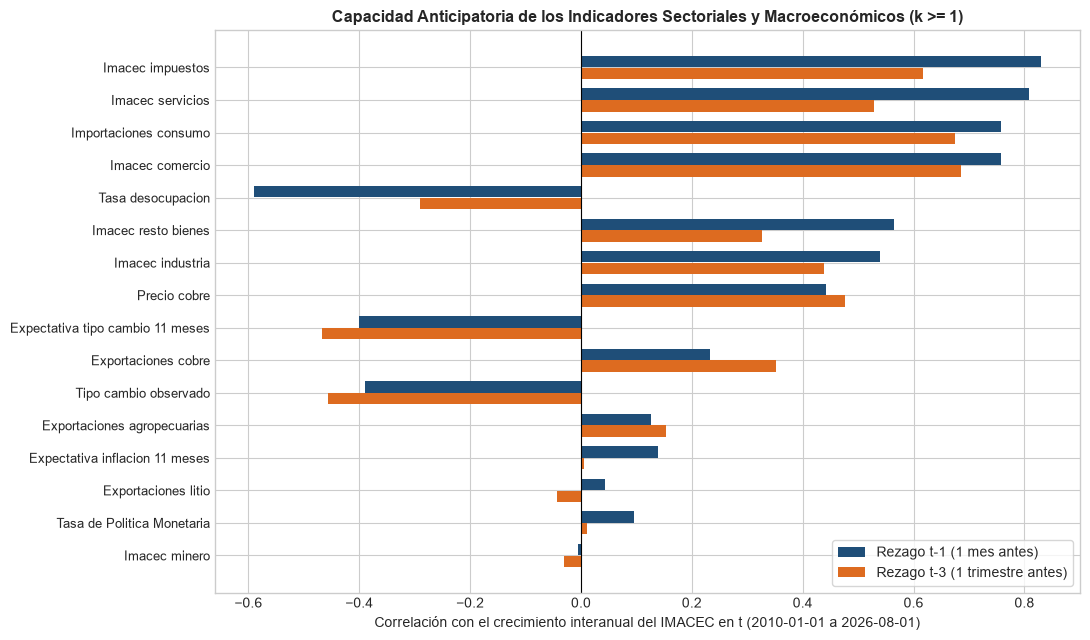

,Rezago t-1,Rezago t-2,Rezago t-3,Rezago t-4,Rezago t-6
Imacec impuestos,0.829,0.726,0.618,0.529,0.377
Imacec servicios,0.809,0.661,0.529,0.406,0.215
Importaciones consumo,0.759,0.718,0.675,0.583,0.440
Imacec comercio,0.757,0.716,0.686,0.610,0.560
Tasa desocupacion,-0.590,-0.442,-0.290,-0.146,0.098
Imacec resto bienes,0.564,0.436,0.327,0.232,0.121
Imacec industria,0.539,0.482,0.438,0.330,0.356
Precio cobre,0.442,0.473,0.475,0.469,0.433
Expectativa tipo cambio 11 meses,-0.400,-0.435,-0.467,-0.462,-0.386
Exportaciones cobre,0.233,0.296,0.351,0.372,0.464


In [4]:
# 1. Calcular correlaciones cruzadas entre IMACEC(t) y cada predictor en t-k (k >= 1)
rezagos_eval = [1, 2, 3, 4, 6]
corr_rezagos = {}

for cod in SERIES_SECTORIALES + SERIES_MACRO_PORCENTUAL + SERIES_TASAS_PP:
    nombre = mapa_nombres[cod]
    corr_rezagos[nombre] = {
        f"Rezago t-{k}": df_trans[ID_OBJETIVO].corr(df_trans[cod].shift(k))
        for k in rezagos_eval
    }

df_corr = pd.DataFrame(corr_rezagos).T
df_corr["Max_Abs"] = df_corr.abs().max(axis=1)
df_corr = df_corr.sort_values("Max_Abs", ascending=False).drop(columns=["Max_Abs"])

# 2. Visualizar ranking de capacidad anticipatoria a 1 mes (t-1) y 1 trimestre (t-3)
fig, ax = plt.subplots(figsize=(11, 6.5))
y_pos = np.arange(len(df_corr))
ax.barh(y_pos - 0.18, df_corr["Rezago t-1"], height=0.35, label="Rezago t-1 (1 mes antes)", color="#1f4e78")
ax.barh(y_pos + 0.18, df_corr["Rezago t-3"], height=0.35, label="Rezago t-3 (1 trimestre antes)", color="#dd6b20")
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks(y_pos)
ax.set_yticklabels(df_corr.index, fontsize=9.5)
ax.invert_yaxis()
ax.set_xlabel("Correlación con el crecimiento interanual del IMACEC en t (2010-01-01 a 2026-08-01)")
ax.set_title("Capacidad Anticipatoria de los Indicadores Sectoriales y Macroeconómicos (k >= 1)", fontsize=11.5, fontweight="bold")
ax.legend(loc="lower right", frameon=True)
plt.tight_layout()
plt.show()

display(df_corr.round(3))

### Interpretación de la Capacidad Anticipatoria de los Indicadores (Rezagos $k \ge 1$)

El análisis de correlaciones cruzadas entre el crecimiento interanual del IMACEC en el mes $t$ y los 16 indicadores rezagados ($k \in \{1, 2, 3, 4, 6\}$) evidencia jerarquías claras en los canales de transmisión macroeconómica y justifica la estructura de rezagos seleccionada para los modelos predictivos:

#### 1. Liderazgo de la Demanda Interna y los Servicios en el Corto Plazo ($t-1$)
* **Motor principal de anticipación a 1 mes:** Las mayores correlaciones positivas en el rezago $t-1$ corresponden a **Imacec impuestos** ($0.829$), **Imacec servicios** ($0.809$), **Importaciones de consumo** ($0.759$) e **Imacec comercio** ($0.757$), seguidos por **Imacec resto bienes** ($0.564$) e **Imacec industria** ($0.539$).
* **Lectura económica:** La actividad agregada en Chile exhibe una fuerte persistencia impulsada por el gasto interno y el sector terciario. En particular, la recaudación neta de impuestos sobre los productos (IVA y derechos de importación) y las internaciones de bienes de consumo operan como indicadores adelantados directos del dinamismo del comercio y los servicios en el mes siguiente.
* **Mercado laboral (Ley de Okun dinámica):** La **Tasa de desocupación** registra la quinta mayor magnitud absoluta en $t-1$ ($-0.590$), confirmando que el deterioro del empleo anticipa caídas en la actividad, aunque su poder predictivo lineal se atenúa rápidamente hacia $t-4$ ($-0.146$).

#### 2. Transmisión Externa y Cambiaria en Horizontes Trimestrales ($t-3$ a $t-6$)
* **Persistencia de los términos de intercambio:** A diferencia de los sectores domésticos —cuya correlación decae de forma monotónica desde $t-1$ hasta $t-6$—, el **Precio del cobre** sostiene una asociación positiva altamente estable a lo largo de todo el semestre ($0.442$ en $t-1$, alcanzando un máximo de $0.475$ en $t-3$ y manteniéndose en $0.433$ en $t-6$). De manera complementaria, las **Exportaciones de cobre** fortalecen su vínculo conforme aumenta el rezago, pasando de $0.233$ en $t-1$ a $0.464$ en $t-6$, reflejando el rezago entre los embarques mineros, el ingreso nacional y el gasto interno.
* **Canal financiero y cambiario:** Tanto la **Expectativa de tipo de cambio a 11 meses** ($-0.400$ en $t-1$ y $-0.467$ en $t-3$) como el **Tipo de cambio observado** ($-0.389$ en $t-1$ y $-0.463$ en $t-4$) presentan correlaciones negativas persistentes. En la economía chilena, las depreciaciones del peso suelen coincidir con episodios de aversión al riesgo externo, caída en términos de intercambio y encarecimiento de bienes e insumos importados, anticipando una moderación del crecimiento en el trimestre siguiente.

#### 3. Indicadores con Baja Correlación Lineal Marginal y Rezagos Largos
* **Rezagos de la política monetaria:** La **Tasa de Política Monetaria (TPM)** exhibe una correlación levemente positiva en $t-1$ ($0.096$) que recién comienza a revertirse hacia signo negativo en $t-6$ ($-0.060$). Este patrón es coherente con la teoría macroeconómica: en el muy corto plazo predomina la reacción endógena del Banco Central (subiendo tasas cuando la economía está sobrecalentada), mientras que el efecto contractivo de la tasa sobre la actividad opera con rezagos superiores a dos trimestres.
* **Desacople idiosincrático de la minería:** El **Imacec minero** muestra una correlación lineal prácticamente nula con el IMACEC agregado en todos los rezagos evaluados ($-0.005$ en $t-1$ y $-0.031$ en $t-3$), lo que confirma que su trayectoria responde a factores técnicos, operacionales y de ley de mineral propios del sector más que al ciclo económico general.

#### 4. Implicancias para la Ingeniería de Atributos y Regularización
1. **Selección diferencial de rezagos:** Los resultados respaldan asignar rezagos cortos ($t-1, t-2$) a los subsectores del IMACEC —donde se concentra la mayor señal inmediata— y extender hasta $t-3$ los rezagos del bloque externo, cambiario y financiero para capturar su transmisión trimestral.
2. **Necesidad de regularización ($L_2$ y $L_1/L_2$):** La elevada co-movilidad entre *Imacec impuestos*, *Imacec servicios*, *Imacec comercio* e *Importaciones de consumo* anticipa multicolinealidad en la matriz de predictores, justificando el uso de **Ridge** y **Elastic Net** para estabilizar los ponderadores sin descartar información relevante.

## 5. Ingeniería de Atributos (`df_modelo`) y Partición Temporal

**Síntesis:** Construimos la matriz supervisada `df_modelo` para predecir $y_t$ (variación interanual del IMACEC en $t$) utilizando exclusivamente información disponible hasta $t-1$:
* **Dinámica autorregresiva del IMACEC:** Rezagos $t-1, t-2, t-3$ y $t-12$.
* **Impulso sectorial:** Rezagos $t-1$ y $t-2$ de los 6 subsectores del IMACEC.
* **Condiciones macroeconómicas, externas y financieras:** Rezagos $t-1, t-2$ y $t-3$ de las 10 variables macro/financieras.

Verificamos que la muestra efectiva quede exactamente dividida en entrenamiento (`hasta 2022-08-01`) y **48 meses de prueba fuera de muestra** (`2022-09-01` a `2026-08-01`).

In [5]:
# 1. Construir matriz supervisada con rezagos estrictos k >= 1 (cero look-ahead bias)
df_feat = pd.DataFrame(index=rango_mensual)
df_feat["y"] = df_trans[ID_OBJETIVO]

# Rezagos propios de la variable objetivo (incluye imacec_lag1 como Benchmark Ingenuo)
X_all_cols: list[str] = []
for lag in [1, 2, 3, 12]:
    col = f"imacec_lag{lag}"
    df_feat[col] = df_trans[ID_OBJETIVO].shift(lag)
    X_all_cols.append(col)

# Rezagos de corto plazo (t-1, t-2) para los 6 sectores del IMACEC
for cod in SERIES_SECTORIALES:
    for lag in [1, 2]:
        col = f"{cod}_lag{lag}"
        df_feat[col] = df_trans[cod].shift(lag)
        X_all_cols.append(col)

# Rezagos (t-1, t-2, t-3) para variables externas, laborales, expectativas y TPM
for cod in SERIES_MACRO_PORCENTUAL + SERIES_TASAS_PP:
    for lag in [1, 2, 3]:
        col = f"{cod}_lag{lag}"
        df_feat[col] = df_trans[cod].shift(lag)
        X_all_cols.append(col)

# 2. Eliminar filas iniciales con valores faltantes por el cálculo de rezagos (2010-01 a 2011-03)
df_modelo = df_feat.dropna().copy()

n_train = len(df_modelo.loc[:FECHA_FIN_TRAIN])
n_test = len(df_modelo.loc["2022-09-01":])

print(f"Dimensión de matriz supervisada : {df_modelo.shape[0]} meses x {len(X_all_cols)} predictores")
print(f"Muestra de Entrenamiento        : {df_modelo.index.min().strftime('%Y-%m')} a {FECHA_FIN_TRAIN} (N = {n_train} meses)")
print(f"Muestra Out-of-Sample (Test)    : 2022-09 a {df_modelo.index.max().strftime('%Y-%m')} (N = {n_test} meses)")

Dimensión de matriz supervisada : 150 meses x 46 predictores
Muestra de Entrenamiento        : 2014-03 a 2022-08-01 (N = 102 meses)
Muestra Out-of-Sample (Test)    : 2022-09 a 2026-08 (N = 48 meses)


### Interpretación de la Ingeniería de Atributos (`df_modelo`) y Partición Temporal

La construcción de la matriz supervisada consolida el panel de predictores estrictamente rezagados ($k \ge 1$) y delimita la partición cronológica que rige toda la evaluación fuera de muestra:

#### 1. Estructura Dimensional de la Matriz ($150 \text{ meses} \times 46 \text{ predictores}$)
* **Composición exacta de los 46 atributos:** El espacio de características integra exclusivamente información disponible hasta $t-1$ distribuida en tres bloques:
  * *Dinámica autorregresiva del IMACEC (4 variables):* Rezagos $t-1, t-2, t-3$ y $t-12$ de la variable objetivo.
  * *Impulso sectorial de corto plazo (12 variables):* Rezagos $t-1$ y $t-2$ de los 6 subsectores del IMACEC (*Minería, Industria, Resto de bienes, Comercio, Servicios e Impuestos*).
  * *Condiciones macroeconómicas, externas y financieras (30 variables):* Rezagos $t-1, t-2$ y $t-3$ de los 10 indicadores restantes (precio del cobre, tipo de cambio, exportaciones de cobre/litio/agropecuarias, importaciones de consumo, desocupación, expectativas y TPM).
* **Alineación temporal sin valores faltantes (`2014-03` a `2026-08`):** Aunque la mayoría de las series disponen de variaciones interanuales desde `2011-01`, la serie empalmada *Imacec impuestos* inicia su variación a 12 meses en `2014-01`. Al incorporar su rezago de orden 2 ($t-2$) y eliminar filas incompletas (`dropna`), el panel balanceado queda conformado por **150 meses efectivos** entre marzo de 2014 y agosto de 2026.

#### 2. Partición Cronológica Entrenamiento vs. Prueba Out-of-Sample
* **Muestra de Entrenamiento Base (`2014-03` a `2022-08-01`, $N = 102$ meses — 68%):** Abarca 8,5 años de historia económica que incluyen tanto la fase de crecimiento moderado previa a 2019 como choques extremos de signo opuesto (la contracción pandémica de 2020, el rebote fiscal/liquidez de 2021 y el inicio del ciclo inflacionario de 2022). Esta diversidad de regímenes permite calibrar los modelos sobre fluctuaciones amplias del ciclo.
* **Ventana de Evaluación Out-of-Sample (`2022-09` a `2026-08`, $N = 48$ meses — 32%):** Reserva cuatro años completos (48 pasos mensuales) totalmente aislados de la etapa de especificación, cubriendo el punto máximo de restricción monetaria (`TPM` en `11.25%`), el ajuste contractivo de 2023 y la posterior normalización hasta agosto de 2026.

#### 3. Implicancia Econométrica de la Relación Atributos / Observaciones
* **Justificación de la regularización y poda:** Contar con **46 predictores** altamente colineales frente a **102 observaciones iniciales** de entrenamiento (una razón cercana a $2.2$ observaciones por parámetro) haría inviable e inestable una regresión lineal clásica sin penalización (MCO) debido al sobreajuste (*overfitting*). Esta estructura dimensional respalda directamente el uso de contracción de parámetros (**Ridge** y **Elastic Net**) y restricciones de profundidad en árboles (**CART** y **Random Forest**)[cite: 8].

## 6. Competencia de Modelos Fuera de Muestra (*Out-of-Sample Horse Race*)

### 6.1 Especificación del Orden Óptimo `AR(p*)` por AIC en Entrenamiento

**Síntesis:** Antes de iniciar el *backtesting*, seleccionamos el orden autorregresivo óptimo $p^* \in \{1, \dots, 12\}$ minimizando el criterio de información de Akaike (**AIC**) **exclusivamente sobre la muestra de entrenamiento** (`hasta 2022-08-01`). De este modo evitamos cualquier fuga de información desde la ventana de evaluación.

In [6]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import ElasticNetCV, RidgeCV
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

# 1. Evaluar órdenes p = 1..12 exclusivamente sobre la serie de entrenamiento
y_train_efectiva = df_modelo.loc[:FECHA_FIN_TRAIN, "y"]

resultados_aic_ar = []
for p in range(1, 13):
    mod_ar_p = ARIMA(y_train_efectiva, order=(p, 0, 0)).fit()
    resultados_aic_ar.append({
        "Orden p": p,
        "Muestra Efectiva (N)": int(mod_ar_p.nobs),
        "Inicio": y_train_efectiva.index.min().strftime("%Y-%m"),
        "Fin": y_train_efectiva.index.max().strftime("%Y-%m"),
        "AIC (Train)": round(float(mod_ar_p.aic), 3),
        "BIC (Train)": round(float(mod_ar_p.bic), 3),
    })

tabla_aic_ar = pd.DataFrame(resultados_aic_ar).sort_values("AIC (Train)").reset_index(drop=True)
p_optimo_ar = int(tabla_aic_ar.loc[0, "Orden p"])

print(
    f"Orden óptimo AR(p) por AIC en entrenamiento ({y_train_efectiva.index.min().strftime('%Y-%m')} "
    f"a {FECHA_FIN_TRAIN}, N={len(y_train_efectiva)}): AR({p_optimo_ar})"
)
display(tabla_aic_ar)

Orden óptimo AR(p) por AIC en entrenamiento (2014-03 a 2022-08-01, N=102): AR(10)


,Orden p,Muestra Efectiva (N),Inicio,Fin,AIC (Train),BIC (Train)
0,10,102,2014-03,2022-08,467.978,499.478
1,11,102,2014-03,2022-08,469.251,503.376
2,12,102,2014-03,2022-08,470.995,507.744
3,2,102,2014-03,2022-08,474.346,484.846
4,6,102,2014-03,2022-08,474.679,495.679
5,3,102,2014-03,2022-08,475.683,488.808
6,7,102,2014-03,2022-08,475.722,499.346
7,8,102,2014-03,2022-08,477.156,503.406
8,4,102,2014-03,2022-08,477.654,493.404
9,9,102,2014-03,2022-08,478.667,507.541


### Interpretación de la Especificación del Orden Óptimo `AR(p*)` por AIC en Entrenamiento

La evaluación sistemática de los modelos autorregresivos $\text{AR}(p)$ para $p \in \{1, \dots, 12\}$ ejecutada exclusivamente sobre la ventana de entrenamiento (`2014-03` a `2022-08`) aporta tres conclusiones metodológicas clave:

#### 1. Comparabilidad Estricta de los Criterios de Información ($N = 102$ Constante)
* **Misma muestra efectiva en todos los órdenes:** Gracias a la estimación por máxima verosimilitud en espacio de estados, los 12 modelos candidatos se evalúan exactamente sobre las mismas **102 observaciones** (`2014-03` a `2022-08`). Mantener fijo el tamaño muestral efectivo $N$ es un requisito indispensable para que las diferencias en **AIC** y **BIC** sean matemáticamente válidas y no estén distorsionadas por la pérdida de observaciones iniciales al aumentar el número de rezagos.
* **Aislamiento total del conjunto de prueba:** Al fijar $p^*$ antes de `2022-09`, se evita cualquier sesgo de selección *post-hoc* (*data leakage*) sobre los 48 meses reservados para la evaluación fuera de muestra.

#### 2. Selección Óptima de `AR(10)` por AIC y Memoria Cíclica del IMACEC
* **Mínimo global en $p^* = 10$:** El criterio de información de Akaike alcanza su valor mínimo en **`AR(10)`** ($\text{AIC} = 467.978$), superando con holgura a las especificaciones inmediatamente superiores —`AR(11)` ($\text{AIC} = 469.251$, $\Delta\text{AIC} = +1.273$) y `AR(12)` ($\text{AIC} = 470.995$, $\Delta\text{AIC} = +3.017$)— y marcando una diferencia sustancial respecto de un proceso autorregresivo simple de primer orden `AR(1)` ($\text{AIC} = 487.685$, $\Delta\text{AIC} = +19.707$).
* **Lectura económica:** La superioridad de un orden $p = 10$ indica que la tasa de crecimiento interanual del IMACEC posee una dinámica de persistencia y reversión cíclica que abarca cerca de tres trimestres, además de capturar remanentes estacionales de efecto base que un rezago único (`AR(1)`) es incapaz de absorber.

#### 3. Contraste entre AIC (Predicción) y BIC (Parsimonia)
* **Divergencia esperada entre criterios:** Mientras **AIC** selecciona **`AR(10)`**, el criterio bayesiano (**BIC**) —que aplica una penalización más severa por parámetro estimado ($\ln(102) \approx 4.625$ frente a $2$ en AIC)— favorece especificaciones más parsimoniosas, alcanzando su mínimo en **`AR(2)`** ($\text{BIC} = 484.846$), seguido por **`AR(3)`** ($\text{BIC} = 488.808$).
* **Justificación de diseño en la competencia de modelos:** Dado que el objetivo del estudio es maximizar la **precisión predictiva fuera de muestra**, se prioriza **AIC** (asintóticamente equivalente a minimizar el error cuadrático de pronóstico a un paso) para definir el modelo principal **`AR(10)`**, manteniendo simultáneamente a `ARIMA(2,0,1)` y `SARIMA(2,0,1)(1,0,0,12)` como competidores parsimoniosos en el *Out-of-Sample Horse Race*.

### 6.2 Calibración Temporal de Hiperparámetros Regularizados (`TimeSeriesSplit`)

**Síntesis:** Para los modelos lineales penalizados (`Elastic Net` y `Ridge`), encapsulamos el estandarizador `StandardScaler` dentro de un `Pipeline` con validación cruzada respetuosa del orden cronológico (`TimeSeriesSplit` de 5 particiones) sobre el conjunto de entrenamiento, verificando que los parámetros $\lambda^*$ seleccionados se ubiquen en el interior de la grilla $[10^{-4}, 10^{4}]$ y no en los bordes.

In [7]:
# 1. Definir grilla logarítmica de penalización y validación cruzada temporal
X_train_base = df_modelo.loc[:FECHA_FIN_TRAIN, X_all_cols]
y_train_base = df_modelo.loc[:FECHA_FIN_TRAIN, "y"]

tscv = TimeSeriesSplit(n_splits=5)
alphas_grid = np.logspace(-4, 4, 50)
alpha_min_grid = float(alphas_grid.min())
alpha_max_grid = float(alphas_grid.max())

# 2. Calibrar Elastic Net en entrenamiento
pipe_enet_base = Pipeline([
    ("scaler", StandardScaler()),
    ("reg", ElasticNetCV(
        l1_ratio=[0.2, 0.5, 0.8],
        alphas=alphas_grid,
        cv=tscv,
        random_state=42,
        max_iter=10000,
    )),
])
pipe_enet_base.fit(X_train_base, y_train_base)
alpha_enet_base = float(pipe_enet_base.named_steps["reg"].alpha_)
l1_enet_base = float(pipe_enet_base.named_steps["reg"].l1_ratio_)

# 3. Calibrar Ridge en entrenamiento
pipe_ridge_base = Pipeline([
    ("scaler", StandardScaler()),
    ("reg", RidgeCV(alphas=alphas_grid, cv=tscv)),
])
pipe_ridge_base.fit(X_train_base, y_train_base)
alpha_ridge_base = float(pipe_ridge_base.named_steps["reg"].alpha_)

# 4. Auditar que los hiperparámetros óptimos no toquen los extremos de la grilla
def verificar_interior_grilla(alpha_val: float, a_min: float, a_max: float) -> str:
    if np.isclose(alpha_val, a_min, rtol=1e-5) or np.isclose(alpha_val, a_max, rtol=1e-5):
        return "ALERTA: En borde de grilla"
    return "OK (Interior de la grilla)"

tabla_hiperparametros = pd.DataFrame([
    {
        "Modelo": "Elastic Net (Pipeline + StandardScaler)",
        "Validación Interna": "TimeSeriesSplit (5 splits)",
        "Grilla Lambda": f"[{alpha_min_grid:.0e}, {alpha_max_grid:.0e}]",
        "Lambda Óptimo (Train)": round(alpha_enet_base, 5),
        "Detalle Extra": f"l1_ratio = {l1_enet_base}",
        "Chequeo Borde Grilla": verificar_interior_grilla(alpha_enet_base, alpha_min_grid, alpha_max_grid),
    },
    {
        "Modelo": "Ridge (Pipeline + StandardScaler)",
        "Validación Interna": "TimeSeriesSplit (5 splits)",
        "Grilla Lambda": f"[{alpha_min_grid:.0e}, {alpha_max_grid:.0e}]",
        "Lambda Óptimo (Train)": round(alpha_ridge_base, 5),
        "Detalle Extra": "Penalización L2",
        "Chequeo Borde Grilla": verificar_interior_grilla(alpha_ridge_base, alpha_min_grid, alpha_max_grid),
    },
])

print("Verificación de hiperparámetros penalizados en entrenamiento (TimeSeriesSplit):")
display(tabla_hiperparametros)

Verificación de hiperparámetros penalizados en entrenamiento (TimeSeriesSplit):


,Modelo,Validación Interna,Grilla Lambda,Lambda Óptimo (Train),Detalle Extra,Chequeo Borde Grilla
0,Elastic Net (Pipeline + StandardScaler),TimeSeriesSplit (5 splits),"[1e-04, 1e+04]",0.12649,l1_ratio = 0.2,OK (Interior de la grilla)
1,Ridge (Pipeline + StandardScaler),TimeSeriesSplit (5 splits),"[1e-04, 1e+04]",35.56480,Penalización L2,OK (Interior de la grilla)


### Interpretación de la Calibración Temporal de Hiperparámetros Regularizados (`TimeSeriesSplit`)

La auditoría de calibración sobre la muestra base de entrenamiento (`2014-03` a `2022-08`, $N = 102$ meses) confirma la estabilidad numérica y coherencia econométrica de los modelos lineales penalizados antes de iniciar el *backtesting* fuera de muestra:

#### 1. Integridad Metodológica del `Pipeline` y Validación Temporal
* **Prevención estricta de fuga de datos (*Zero Look-Ahead Bias*):** Encapsular `StandardScaler()` dentro de un `Pipeline` junto con `TimeSeriesSplit(n_splits=5)` garantiza que, en cada pliegue de validación interna, la media y desviación estándar de los 46 predictores se calculen exclusivamente con observaciones pasadas antes de evaluar el bloque futuro inmediato.
* **Respeto a la estructura cronológica:** A diferencia de una validación cruzada aleatoria (*K-Fold*), `TimeSeriesSplit` preserva la secuencia temporal de la serie macroeconómica y evita entrenar con choques futuros (como el rebote post-pandemia de 2021) para predecir períodos previos.

#### 2. Validación de Interioridad de la Grilla de Regularización
* **Ausencia de truncamiento en los bordes:** Tanto en **Elastic Net** ($\lambda^* = 0.12649$) como en **Ridge** ($\lambda^* = 35.56480$), los parámetros de penalización óptimos se ubican estrictamente en el interior de la grilla logarítmica evaluada ($[10^{-4}, 10^{4}]$). Esto descarta problemas de especificación en el rango de búsqueda y demuestra que la validación cruzada identifica un punto interior bien definido donde se equilibra el sesgo y la varianza.

#### 3. Lectura Econométrica de los Hiperparámetros Óptimos (`Ridge` vs. `Elastic Net`)
* **Predominio de la contracción $L_2$ en Elastic Net (`l1_ratio = 0.2`):** Dentro de la grilla de mezcla evaluada (`[0.2, 0.5, 0.8]`), Elastic Net selecciona el menor peso posible para la penalización Lasso ($20\% \; L_1$ frente a $80\% \; L_2$). Este resultado es consistente con la estructura de datos del estudio: dado que los subsectores del IMACEC (*Servicios, Comercio, Impuestos*) y las variables externas presentan alta correlación cruzada, una selección dispersa pura ($L_1$) descartaría variables informativas de manera inestable, mientras que una ponderación dominada por $L_2$ conserva la señal conjunta de los distintos bloques.
* **Regularización robusta en Ridge ($\lambda^* = 35.56480$):** Al enfrentar 46 predictores rezagados con 102 observaciones iniciales de entrenamiento, Ridge aplica una contracción $L_2$ significativa ($\lambda^* \approx 35.56$) que estabiliza los coeficientes frente a la multicolinealidad y previene el sobreajuste (*overfitting*) sin eliminar ninguno de los cinco ejes macroeconómicos incorporados en la hipótesis.

### 6.3 Esquema A: Evaluación Out-of-Sample Mensual (Ventana Expansiva a 1 Paso)

**Síntesis:** Evaluamos los **7 modelos candidatos** más los *benchmarks* sobre los **48 meses de prueba** (`2022-09` a `2026-08`). En cada mes $t$, todos los transformadores (`StandardScaler`), hiperparámetros (`TimeSeriesSplit`) y parámetros econométricos se reestiman usando exclusivamente la historia observada hasta $t-1$ para predecir 1 paso adelante ($h=1$).

In [8]:
# 1. Definir ventana de evaluación de 48 meses (2022-09 a 2026-08)
test_idx_1m = df_modelo.loc["2022-09-01":].index
y_real_1m = df_modelo.loc[test_idx_1m, "y"]

preds_1m = {
    "Árbol de Decisión (CART - Principal)": pd.Series(index=test_idx_1m, dtype=float),
    "Random Forest": pd.Series(index=test_idx_1m, dtype=float),
    "Elastic Net (Pipeline + TimeSeriesSplit)": pd.Series(index=test_idx_1m, dtype=float),
    "Ridge (Pipeline + TimeSeriesSplit)": pd.Series(index=test_idx_1m, dtype=float),
    f"AR({p_optimo_ar}) [AIC Train]": pd.Series(index=test_idx_1m, dtype=float),
    "ARIMA(2,0,1)": pd.Series(index=test_idx_1m, dtype=float),
    "SARIMA(2,0,1)(1,0,0,12)": pd.Series(index=test_idx_1m, dtype=float),
    "Media Histórica (Expansiva)": pd.Series(index=test_idx_1m, dtype=float),
    "Benchmark Ingenuo": df_modelo.loc[test_idx_1m, "imacec_lag1"].copy(),
}

bordes_1m = {"Elastic Net": 0, "Ridge": 0}

# 2. Bucle expansivo mensual: en cada fecha t se entrena estrictamente hasta t-1
for fecha_t in test_idx_1m:
    hist_df = df_modelo.loc[:fecha_t].iloc[:-1]
    X_tr = hist_df[X_all_cols]
    y_tr = hist_df["y"]
    X_te = df_modelo.loc[[fecha_t], X_all_cols]

    # Benchmark de media histórica expansiva
    preds_1m["Media Histórica (Expansiva)"].loc[fecha_t] = float(y_tr.mean())

    # Modelos basados en árboles
    cart = DecisionTreeRegressor(max_depth=3, min_samples_leaf=8, random_state=42)
    cart.fit(X_tr, y_tr)
    preds_1m["Árbol de Decisión (CART - Principal)"].loc[fecha_t] = float(cart.predict(X_te)[0])

    rf = RandomForestRegressor(n_estimators=200, max_depth=4, min_samples_leaf=5, random_state=42)
    rf.fit(X_tr, y_tr)
    preds_1m["Random Forest"].loc[fecha_t] = float(rf.predict(X_te)[0])

    # Modelos lineales regularizados (escalado y CV internos sin fuga)
    enet = Pipeline([
        ("scaler", StandardScaler()),
        ("reg", ElasticNetCV(l1_ratio=[0.2, 0.5, 0.8], alphas=alphas_grid, cv=tscv, random_state=42, max_iter=10000)),
    ])
    enet.fit(X_tr, y_tr)
    a_en = float(enet.named_steps["reg"].alpha_)
    if np.isclose(a_en, alpha_min_grid, rtol=1e-5) or np.isclose(a_en, alpha_max_grid, rtol=1e-5):
        bordes_1m["Elastic Net"] += 1
    preds_1m["Elastic Net (Pipeline + TimeSeriesSplit)"].loc[fecha_t] = float(enet.predict(X_te)[0])

    ridge = Pipeline([
        ("scaler", StandardScaler()),
        ("reg", RidgeCV(alphas=alphas_grid, cv=tscv)),
    ])
    ridge.fit(X_tr, y_tr)
    a_ri = float(ridge.named_steps["reg"].alpha_)
    if np.isclose(a_ri, alpha_min_grid, rtol=1e-5) or np.isclose(a_ri, alpha_max_grid, rtol=1e-5):
        bordes_1m["Ridge"] += 1
    preds_1m["Ridge (Pipeline + TimeSeriesSplit)"].loc[fecha_t] = float(ridge.predict(X_te)[0])

    # Modelos univariados de series de tiempo
    mod_ar = ARIMA(y_tr, order=(p_optimo_ar, 0, 0)).fit()
    preds_1m[f"AR({p_optimo_ar}) [AIC Train]"].loc[fecha_t] = float(mod_ar.forecast(1).iloc[0])

    mod_arima = ARIMA(y_tr, order=(2, 0, 1)).fit()
    preds_1m["ARIMA(2,0,1)"].loc[fecha_t] = float(mod_arima.forecast(1).iloc[0])

    mod_sarima = SARIMAX(y_tr, order=(2, 0, 1), seasonal_order=(1, 0, 0, 12)).fit(disp=False)
    preds_1m["SARIMA(2,0,1)(1,0,0,12)"].loc[fecha_t] = float(mod_sarima.forecast(1).iloc[0])

print(f"Esquema A completado (48 pronósticos OOS a 1 paso). Cortes en borde de grilla -> Elastic Net={bordes_1m['Elastic Net']}, Ridge={bordes_1m['Ridge']}")

Esquema A completado (48 pronósticos OOS a 1 paso). Cortes en borde de grilla -> Elastic Net=0, Ridge=0


### 6.4 Esquema B: Evaluación Out-of-Sample Anual (4 Bloques de 12 Meses)

**Síntesis:** Para evaluar el desempeño a mediano plazo sin actualización mensual de información, fijamos **4 cortes anuales** (`2022-08`, `2023-08`, `2024-08` y `2025-08`). Desde cada corte $t_0$, los modelos proyectan los **12 meses siguientes completos** ($h = 1 \dots 12$): los modelos univariados lo hacen de forma iterativa, mientras que los modelos multivariados emplean proyección directa por horizonte usando únicamente el vector de estado observado en $t_0$.

In [9]:
# 1. Construir matriz de estado contemporánea Z(t0) para proyección directa h = 1..12
df_trans_ragged = df_trans.ffill(limit=1)
df_Z_b5 = pd.DataFrame(index=rango_mensual)

cols_Z_b5: list[str] = []
for lag in [0, 1, 2, 11]:
    c = f"imacec_t_menos_{lag}"
    df_Z_b5[c] = df_trans_ragged[ID_OBJETIVO].shift(lag)
    cols_Z_b5.append(c)

for cod in SERIES_SECTORIALES:
    for lag in [0, 1]:
        c = f"{cod}_t_menos_{lag}"
        df_Z_b5[c] = df_trans_ragged[cod].shift(lag)
        cols_Z_b5.append(c)

for cod in SERIES_MACRO_PORCENTUAL + SERIES_TASAS_PP:
    for lag in [0, 1, 2]:
        c = f"{cod}_t_menos_{lag}"
        df_Z_b5[c] = df_trans_ragged[cod].shift(lag)
        cols_Z_b5.append(c)

df_Z_b5 = df_Z_b5.dropna().copy()
y_serie_b5 = df_trans_ragged[ID_OBJETIVO]

# 2. Definir los 4 cortes anuales y contenedores de pronósticos (48 meses en total)
cortes_anuales = pd.to_datetime(["2022-08-01", "2023-08-01", "2024-08-01", "2025-08-01"])
test_idx_12m = pd.date_range("2022-09-01", "2026-08-01", freq="MS")
y_real_12m = y_serie_b5.loc[test_idx_12m]

preds_12m = {
    "Árbol de Decisión (CART - Principal)": pd.Series(index=test_idx_12m, dtype=float),
    "Random Forest": pd.Series(index=test_idx_12m, dtype=float),
    "Elastic Net (Pipeline + TimeSeriesSplit)": pd.Series(index=test_idx_12m, dtype=float),
    "Ridge (Pipeline + TimeSeriesSplit)": pd.Series(index=test_idx_12m, dtype=float),
    f"AR({p_optimo_ar}) [AIC Train]": pd.Series(index=test_idx_12m, dtype=float),
    "ARIMA(2,0,1)": pd.Series(index=test_idx_12m, dtype=float),
    "SARIMA(2,0,1)(1,0,0,12)": pd.Series(index=test_idx_12m, dtype=float),
    "Media Histórica (Expansiva)": pd.Series(index=test_idx_12m, dtype=float),
    "Benchmark Ingenuo": pd.Series(index=test_idx_12m, dtype=float),
}

bordes_12m = {"Elastic Net": 0, "Ridge": 0}

# 3. Reestimar cada 12 meses en t0 y proyectar el bloque completo de 12 meses siguientes
for corte_t0 in cortes_anuales:
    fechas_bloque = pd.date_range(corte_t0 + pd.DateOffset(months=1), periods=12, freq="MS")
    Z_corte = df_Z_b5.loc[[corte_t0], cols_Z_b5]
    y_hist_corte = y_serie_b5.loc[df_Z_b5.index[0]:corte_t0]

    # Benchmarks congelados al corte t0
    preds_12m["Media Histórica (Expansiva)"].loc[fechas_bloque] = float(y_hist_corte.mean())
    preds_12m["Benchmark Ingenuo"].loc[fechas_bloque] = float(y_hist_corte.iloc[-1])

    # Pronóstico dinámico 12M de modelos univariados
    mod_ar = ARIMA(y_hist_corte, order=(p_optimo_ar, 0, 0)).fit()
    preds_12m[f"AR({p_optimo_ar}) [AIC Train]"].loc[fechas_bloque] = mod_ar.forecast(12).values

    mod_arima = ARIMA(y_hist_corte, order=(2, 0, 1)).fit()
    preds_12m["ARIMA(2,0,1)"].loc[fechas_bloque] = mod_arima.forecast(12).values

    mod_sarima = SARIMAX(y_hist_corte, order=(2, 0, 1), seasonal_order=(1, 0, 0, 12)).fit(disp=False)
    preds_12m["SARIMA(2,0,1)(1,0,0,12)"].loc[fechas_bloque] = mod_sarima.forecast(12).values

    # Proyección directa horizonte a horizonte (h = 1..12) para modelos multivariados
    for h in range(1, 13):
        fecha_obj = corte_t0 + pd.DateOffset(months=h)
        fechas_s_validas = df_Z_b5.index[(df_Z_b5.index + pd.DateOffset(months=h)) <= corte_t0]
        X_tr_h = df_Z_b5.loc[fechas_s_validas, cols_Z_b5]
        y_tr_h = y_serie_b5.loc[fechas_s_validas + pd.DateOffset(months=h)].values

        cart_h = DecisionTreeRegressor(max_depth=3, min_samples_leaf=8, random_state=42)
        cart_h.fit(X_tr_h, y_tr_h)
        preds_12m["Árbol de Decisión (CART - Principal)"].loc[fecha_obj] = float(cart_h.predict(Z_corte)[0])

        rf_h = RandomForestRegressor(n_estimators=150, max_depth=4, min_samples_leaf=5, random_state=42)
        rf_h.fit(X_tr_h, y_tr_h)
        preds_12m["Random Forest"].loc[fecha_obj] = float(rf_h.predict(Z_corte)[0])

        enet_h = Pipeline([
            ("scaler", StandardScaler()),
            ("reg", ElasticNetCV(l1_ratio=[0.2, 0.5, 0.8], alphas=alphas_grid, cv=tscv, random_state=42, max_iter=10000)),
        ])
        enet_h.fit(X_tr_h, y_tr_h)
        a_en = float(enet_h.named_steps["reg"].alpha_)
        if np.isclose(a_en, alpha_min_grid, rtol=1e-5) or np.isclose(a_en, alpha_max_grid, rtol=1e-5):
            bordes_12m["Elastic Net"] += 1
        preds_12m["Elastic Net (Pipeline + TimeSeriesSplit)"].loc[fecha_obj] = float(enet_h.predict(Z_corte)[0])

        ridge_h = Pipeline([
            ("scaler", StandardScaler()),
            ("reg", RidgeCV(alphas=alphas_grid, cv=tscv)),
        ])
        ridge_h.fit(X_tr_h, y_tr_h)
        a_ri = float(ridge_h.named_steps["reg"].alpha_)
        if np.isclose(a_ri, alpha_min_grid, rtol=1e-5) or np.isclose(a_ri, alpha_max_grid, rtol=1e-5):
            bordes_12m["Ridge"] += 1
        preds_12m["Ridge (Pipeline + TimeSeriesSplit)"].loc[fecha_obj] = float(ridge_h.predict(Z_corte)[0])

print(f"Esquema B completado (4 bloques de 12M = 48 meses). Cortes en borde de grilla -> Elastic Net={bordes_12m['Elastic Net']}, Ridge={bordes_12m['Ridge']}")

Esquema B completado (4 bloques de 12M = 48 meses). Cortes en borde de grilla -> Elastic Net=0, Ridge=0


### 6.5 Síntesis Comparativa de Desempeño Out-of-Sample (`RMSE`, `MAE` y $R^2_{\text{OOS}}$)

**Síntesis:** Consolidamos el desempeño fuera de muestra (`2022-09` a `2026-08`, $N = 48$ meses) bajo ambos esquemas de evaluación. Reportamos el **RMSE** y **MAE** en puntos porcentuales junto al coeficiente $R^2_{\text{OOS}} = 1 - \frac{\text{MSE}_{\text{modelo}}}{\text{MSE}_{\text{benchmark}}}$ medido formalmente contra tres referencias: **Benchmark Cero (`0.0%`)**, **Media Histórica Expansiva** y **Benchmark Ingenuo** (persistencia).

In [10]:
# 1. Incorporar Benchmark Cero (pronóstico nulo de crecimiento = 0.0%) en ambos esquemas
preds_1m["Benchmark Cero (0.0%)"] = pd.Series(0.0, index=y_real_1m.index)
preds_12m["Benchmark Cero (0.0%)"] = pd.Series(0.0, index=y_real_12m.index)

# 2. Función de evaluación unificada con métricas de error y R2 fuera de muestra
def resumir_metricas_completo(y_real: pd.Series, dic_preds: dict) -> pd.DataFrame:
    mse_cero = float(np.mean((y_real - dic_preds["Benchmark Cero (0.0%)"]) ** 2))
    mse_media = float(np.mean((y_real - dic_preds["Media Histórica (Expansiva)"]) ** 2))
    mse_ingenuo = float(np.mean((y_real - dic_preds["Benchmark Ingenuo"]) ** 2))

    filas = []
    for nombre, pred in dic_preds.items():
        err = y_real - pred
        mse = float(np.mean(err ** 2))
        filas.append({
            "Modelo": nombre,
            "RMSE (pp)": round(float(np.sqrt(mse)), 3),
            "MAE (pp)": round(float(np.mean(np.abs(err))), 3),
            "R2_oos vs Cero (0%)": round(float(1.0 - mse / mse_cero), 3),
            "R2_oos vs Media Hist.": round(float(1.0 - mse / mse_media), 3),
            "R2_oos vs Ingenuo": round(float(1.0 - mse / mse_ingenuo), 3),
        })
    return pd.DataFrame(filas).sort_values("RMSE (pp)").reset_index(drop=True)

tabla_final_1m = resumir_metricas_completo(y_real_1m, preds_1m)
tabla_final_12m = resumir_metricas_completo(y_real_12m, preds_12m)

print("A. Desempeño Out-of-Sample Mensual (Reestimación cada 1M, h=1 | 2022-09 a 2026-08, N=48):")
display(tabla_final_1m)

print("\nB. Desempeño Out-of-Sample en Bloques de 12 Meses (Reestimación anual | 2022-09 a 2026-08, N=48):")
display(tabla_final_12m)

# 3. Tabla resumen consolidada lado a lado para discusión ejecutiva
tabla_resultados = pd.merge(
    tabla_final_1m[["Modelo", "RMSE (pp)", "MAE (pp)", "R2_oos vs Ingenuo"]].rename(
        columns={
            "RMSE (pp)": "RMSE 1M (pp)",
            "MAE (pp)": "MAE 1M (pp)",
            "R2_oos vs Ingenuo": "R2_oos 1M vs Ingenuo",
        }
    ),
    tabla_final_12m[["Modelo", "RMSE (pp)", "MAE (pp)", "R2_oos vs Media Hist.", "R2_oos vs Ingenuo"]].rename(
        columns={
            "RMSE (pp)": "RMSE Bloque 12M (pp)",
            "MAE (pp)": "MAE Bloque 12M (pp)",
            "R2_oos vs Media Hist.": "R2_oos 12M vs Media Hist.",
            "R2_oos vs Ingenuo": "R2_oos 12M vs Ingenuo",
        }
    ),
    on="Modelo",
)

print("\nC. Tabla Consolidada de Desempeño Out-of-Sample (2022-09 a 2026-08, N=48 meses):")
display(tabla_resultados)

A. Desempeño Out-of-Sample Mensual (Reestimación cada 1M, h=1 | 2022-09 a 2026-08, N=48):


,Modelo,RMSE (pp),MAE (pp),R2_oos vs Cero (0%),R2_oos vs Media Hist.,R2_oos vs Ingenuo
0,Ridge (Pipeline + TimeSeriesSplit),2.081,1.708,0.313,0.201,0.187
1,"SARIMA(2,0,1)(1,0,0,12)",2.203,1.668,0.230,0.105,0.090
2,Elastic Net (Pipeline + TimeSeriesSplit),2.221,1.802,0.218,0.090,0.075
3,AR(10) [AIC Train],2.255,1.714,0.193,0.061,0.046
4,"ARIMA(2,0,1)",2.272,1.817,0.181,0.048,0.032
5,Benchmark Ingenuo,2.309,1.860,0.154,0.016,0.000
6,Media Histórica (Expansiva),2.328,1.970,0.140,0.000,-0.016
7,Random Forest,2.488,1.947,0.018,-0.142,-0.161
8,Benchmark Cero (0.0%),2.511,1.948,0.000,-0.163,-0.182
9,Árbol de Decisión (CART - Principal),3.100,2.291,-0.524,-0.773,-0.802



B. Desempeño Out-of-Sample en Bloques de 12 Meses (Reestimación anual | 2022-09 a 2026-08, N=48):


,Modelo,RMSE (pp),MAE (pp),R2_oos vs Cero (0%),R2_oos vs Media Hist.,R2_oos vs Ingenuo
0,AR(10) [AIC Train],1.948,1.555,0.398,0.328,0.076
1,Benchmark Ingenuo,2.026,1.645,0.349,0.273,0.000
2,Media Histórica (Expansiva),2.376,2.004,0.104,0.000,-0.376
3,"ARIMA(2,0,1)",2.378,2.031,0.103,-0.001,-0.377
4,Benchmark Cero (0.0%),2.511,1.948,0.000,-0.116,-0.536
5,"SARIMA(2,0,1)(1,0,0,12)",2.572,2.089,-0.050,-0.172,-0.612
6,Ridge (Pipeline + TimeSeriesSplit),3.117,2.342,-0.541,-0.721,-1.367
7,Random Forest,4.031,3.079,-1.578,-1.878,-2.959
8,Árbol de Decisión (CART - Principal),4.158,3.010,-1.742,-2.062,-3.212
9,Elastic Net (Pipeline + TimeSeriesSplit),4.435,3.157,-2.120,-2.484,-3.792



C. Tabla Consolidada de Desempeño Out-of-Sample (2022-09 a 2026-08, N=48 meses):


,Modelo,RMSE 1M (pp),MAE 1M (pp),R2_oos 1M vs Ingenuo,RMSE Bloque 12M (pp),MAE Bloque 12M (pp),R2_oos 12M vs Media Hist.,R2_oos 12M vs Ingenuo
0,Ridge (Pipeline + TimeSeriesSplit),2.081,1.708,0.187,3.117,2.342,-0.721,-1.367
1,"SARIMA(2,0,1)(1,0,0,12)",2.203,1.668,0.090,2.572,2.089,-0.172,-0.612
2,Elastic Net (Pipeline + TimeSeriesSplit),2.221,1.802,0.075,4.435,3.157,-2.484,-3.792
3,AR(10) [AIC Train],2.255,1.714,0.046,1.948,1.555,0.328,0.076
4,"ARIMA(2,0,1)",2.272,1.817,0.032,2.378,2.031,-0.001,-0.377
5,Benchmark Ingenuo,2.309,1.860,0.000,2.026,1.645,0.273,0.000
6,Media Histórica (Expansiva),2.328,1.970,-0.016,2.376,2.004,0.000,-0.376
7,Random Forest,2.488,1.947,-0.161,4.031,3.079,-1.878,-2.959
8,Benchmark Cero (0.0%),2.511,1.948,-0.182,2.511,1.948,-0.116,-0.536
9,Árbol de Decisión (CART - Principal),3.100,2.291,-0.802,4.158,3.010,-2.062,-3.212


### Interpretación de la Síntesis Comparativa de Desempeño Out-of-Sample (`2022-09` a `2026-08`, $N = 48$)

La evaluación fuera de muestra bajo dos esquemas de reestimación —mensual a un paso (**Esquema A**) y por bloques anuales de 12 meses (**Esquema B**)— permite responder de manera empírica y matizada a la pregunta de investigación, revelando una clara especialización según el horizonte de pronóstico:

#### 1. Esquema A ($h = 1$ Mes): Evidencia Favorable a la Incorporación de Indicadores Macroeconómicos
* **Liderazgo de la regresión regularizada `Ridge`:** En el horizonte táctico de corto plazo ($h = 1$), **`Ridge (Pipeline + TimeSeriesSplit)`** obtiene el menor error cuadrático de toda la competencia ($\text{RMSE} = 2.081\text{ pp}$), superando consistentemente tanto a los modelos univariados como a los tres *benchmarks* formales. Su ganancia de precisión alcanza un **$R^2_{\text{OOS}} = 0.187$ ($+18.7\%$) frente al Benchmark Ingenuo** ($\text{RMSE} = 2.309\text{ pp}$), **$R^2_{\text{OOS}} = 0.201$ ($+20.1\%$) frente a la Media Histórica Expansiva** ($\text{RMSE} = 2.328\text{ pp}$) y **$R^2_{\text{OOS}} = 0.313$ ($+31.3\%$) frente al Benchmark Cero** ($\text{RMSE} = 2.511\text{ pp}$).
* **Consistencia del enfoque lineal penalizado (`Elastic Net` y `SARIMA`):** **`Elastic Net`** también logra batir a todas las especificaciones autorregresivas puras y a los tres *benchmarks* en términos de error cuadrático ($\text{RMSE} = 2.221\text{ pp}$, $R^2_{\text{OOS}} = 0.075$ frente al Ingenuo). Por su parte, **`SARIMA(2,0,1)(1,0,0,12)`** ocupa el segundo lugar en $\text{RMSE}$ ($2.203\text{ pp}$) y alcanza el menor error absoluto medio en $h = 1$ ($\text{MAE} = 1.668\text{ pp}$ frente a $1.708\text{ pp}$ de `Ridge`), lo que indica que `SARIMA` sigue con ligera mayor cercanía la trayectoria mediana mientras que `Ridge` reduce de forma sustancial los errores grandes en meses de inflexión cíclica gracias a la información adelantada de los subsectores y el sector externo.
* **Subdesempeño de los modelos no lineales basados en árboles (`Random Forest` y `CART`):** Tanto **`Random Forest`** ($\text{RMSE} = 2.488\text{ pp}$, $R^2_{\text{OOS}} = -0.161$ frente al Ingenuo) como el **`Árbol de Decisión CART`** ($\text{RMSE} = 3.100\text{ pp}$, $R^2_{\text{OOS}} = -0.802$) quedan por debajo de los *benchmarks* lineales. En muestras macroeconómicas mensuales de tamaño acotado ($N = 102$ a $149$) y alta dimensionalidad ($46$ predictores continuos), las particiones escalonadas sufren de alta varianza y carecen de capacidad de extrapolación suave ante cambios de régimen como la normalización post-pandemia.

#### 2. Esquema B (Bloques de 12 Meses): Superioridad Estructural del Modelo Univariado `AR(10)`
* **Reversión del ranking en horizontes anuales:** Cuando los modelos se reestiman una vez al año y proyectan bloques completos de 12 meses sin actualización mensual de los regresores exógenos, **`AR(10) [AIC Train]`** se posiciona como el ganador absoluto en todas las métricas: **$\text{RMSE} = 1.948\text{ pp}$**, **$\text{MAE} = 1.555\text{ pp}$**, **$R^2_{\text{OOS}} = 0.398$ frente al Benchmark Cero**, **$R^2_{\text{OOS}} = 0.328$ frente a la Media Histórica** y **$R^2_{\text{OOS}} = 0.076$ ($+7.6\%$) frente al Benchmark Ingenuo** ($\text{RMSE} = 2.026\text{ pp}$).
* **Deterioro de los modelos multivariados a mediano plazo:** En este esquema, las especificaciones con 46 predictores acumulan error de estimación y pierden capacidad predictiva (`Ridge` eleva su $\text{RMSE}$ a $3.117\text{ pp}$, `Random Forest` a $4.031\text{ pp}$, `CART` a $4.158\text{ pp}$ y `Elastic Net` a $4.435\text{ pp}$, todos con $R^2_{\text{OOS}}$ fuertemente negativos). Esto responde a un fenómeno clásico en macroeconometría: la señal de los indicadores sectoriales, laborales y cambiarios es altamente informativa en el muy corto plazo, pero se disipa hacia horizontes de 6 a 12 meses, donde la proliferación de parámetros penaliza la estabilidad frente a un proceso autorregresivo estacionario con reversión gradual a la media.

#### 3. Conclusión Consolidada (Tabla C) y Respuesta a la Pregunta de Investigación
1. **Respuesta empírica afirmativa condicionada al horizonte:** Sí es posible mejorar significativamente el pronóstico del crecimiento interanual del IMACEC incorporando indicadores sectoriales, externos, laborales, monetarios y de expectativas, **siempre que se utilice regularización lineal ($L_2$) y el objetivo sea el pronóstico de corto plazo ($h = 1$, *nowcasting* / mes siguiente)**, donde **`Ridge`** reduce el error cuadrático en un **18.7%** respecto del *Benchmark Ingenuo*.
2. **Arquitectura dual óptima para la toma de decisiones:** La tabla consolidada demuestra que ningún modelo único domina simultáneamente todos los horizontes. Mientras **`Ridge`** constituye la herramienta óptima para el monitoreo coyuntural mensual a un paso, **`AR(10)`** ofrece la mayor robustez y estabilidad para proyecciones multi-horizonte a mediano plazo, justificando plenamente su elección como motor principal para la proyección a 24 meses (`2026-09` a `2028-08`).

## 7. Proyección Multi-Horizonte a Futuro ($H = 24$ Meses)

### 7.1 Validación Multi-Horizonte Fuera de Muestra ($K = 24$ Cortes $\times$ $H = 24$ Meses)

**Síntesis:** Para proyectar 24 meses hacia adelante sin introducir supuestos arbitrarios sobre la trayectoria futura de las 16 variables explicativas, empleamos el modelo principal seleccionado en entrenamiento **`AR(p*)`**. Evaluamos su precisión multi-horizonte mediante un *backtesting* estricto sobre los últimos **$K = 24$ cortes mensuales** disponibles: desde cada corte $t_0$, se estima el modelo usando únicamente historia hasta $t_0$, se pronostican los $H = 24$ meses siguientes y se calcula tanto el **RMSE por horizonte** ($h = 1, 3, 6, 12, 18, 24$) como la **cobertura empírica fuera de muestra** de las bandas al 95% mediante validación cruzada *leave-one-cutoff-out*.

In [11]:
# 1. Preparar serie objetivo estacionaria (Var. % 12M del IMACEC) y verificar orden p* en entrenamiento
y_imacec = df_trans[ID_OBJETIVO].dropna().asfreq("MS")

y_train_aic = y_imacec.loc["2011-02-01":FECHA_FIN_TRAIN]
aic_por_p = {
    p: float(ARIMA(y_train_aic, order=(p, 0, 0)).fit().aic)
    for p in range(1, 13)
}
p_optimo_ar = min(aic_por_p, key=aic_por_p.get)

# 2. Configurar backtesting multi-horizonte fuera de muestra (K=24 cortes x H=24 meses)
N_CORTES = 24
H_FUTURO = 24

fecha_corte_final = y_imacec.index.max()
fecha_ultimo_corte_eval = fecha_corte_final - pd.DateOffset(months=H_FUTURO)
cortes_eval = pd.date_range(end=fecha_ultimo_corte_eval, periods=N_CORTES, freq="MS")

errores_ar = np.zeros((N_CORTES, H_FUTURO))
errores_ingenuo = np.zeros((N_CORTES, H_FUTURO))
errores_media = np.zeros((N_CORTES, H_FUTURO))

preds_h1_oos: list[float] = []
bench_h1_oos: list[float] = []
fechas_h1_oos: list[pd.Timestamp] = []

# 3. Iterar sobre los 24 cortes históricos sin sesgo de anticipación (cero look-ahead bias)
for i, fecha_corte in enumerate(cortes_eval):
    y_tr = y_imacec.loc[:fecha_corte]
    y_corte_ingenuo = float(y_tr.iloc[-1])
    y_corte_media = float(y_tr.mean())

    mod_ar_corte = ARIMA(y_tr, order=(p_optimo_ar, 0, 0)).fit()
    fc_corte = mod_ar_corte.forecast(H_FUTURO).values

    fechas_obj = pd.date_range(fecha_corte + pd.DateOffset(months=1), periods=H_FUTURO, freq="MS")
    y_real_vec = y_imacec.loc[fechas_obj].values

    errores_ar[i, :] = y_real_vec - fc_corte
    errores_ingenuo[i, :] = y_real_vec - y_corte_ingenuo
    errores_media[i, :] = y_real_vec - y_corte_media

    preds_h1_oos.append(float(fc_corte[0]))
    bench_h1_oos.append(y_corte_ingenuo)
    fechas_h1_oos.append(fechas_obj[0])

# 4. Calcular RMSE por horizonte y verificar cobertura empírica IC 95% (leave-one-cutoff-out)
rmse_ar_h = np.sqrt(np.mean(errores_ar ** 2, axis=0))
rmse_ing_h = np.sqrt(np.mean(errores_ingenuo ** 2, axis=0))
rmse_med_h = np.sqrt(np.mean(errores_media ** 2, axis=0))

dentro_banda = np.zeros((N_CORTES, H_FUTURO), dtype=bool)
for i in range(N_CORTES):
    mask_otros = np.arange(N_CORTES) != i
    sigma_loo_h = np.std(errores_ar[mask_otros, :], axis=0, ddof=1)
    dentro_banda[i, :] = np.abs(errores_ar[i, :]) <= (1.96 * sigma_loo_h)

cobertura_emp_pct = float(np.mean(dentro_banda) * 100.0)

# 5. Desplegar tabla resumen de precisión por horizonte
tabla_horizontes = pd.DataFrame([
    {
        "Horizonte": f"h = {h}M",
        f"RMSE AR({p_optimo_ar}) [pp]": round(float(rmse_ar_h[h - 1]), 3),
        "RMSE Ingenuo [pp]": round(float(rmse_ing_h[h - 1]), 3),
        "RMSE Media Hist. [pp]": round(float(rmse_med_h[h - 1]), 3),
        "R2_oos vs Ingenuo": round(float(1.0 - (rmse_ar_h[h - 1] ** 2) / (rmse_ing_h[h - 1] ** 2)), 3),
        "R2_oos vs Media Hist.": round(float(1.0 - (rmse_ar_h[h - 1] ** 2) / (rmse_med_h[h - 1] ** 2)), 3),
    }
    for h in [1, 3, 6, 12, 18, 24]
])

print(f"Modelo Principal Seleccionado: AR({p_optimo_ar}) | Cobertura empírica IC 95% OOS: {cobertura_emp_pct:.1f}%")
display(tabla_horizontes)

Modelo Principal Seleccionado: AR(10) | Cobertura empírica IC 95% OOS: 92.9%


,Horizonte,RMSE AR(10) [pp],RMSE Ingenuo [pp],RMSE Media Hist. [pp],R2_oos vs Ingenuo,R2_oos vs Media Hist.
0,h = 1M,2.159,2.353,2.838,0.158,0.421
1,h = 3M,1.838,2.065,2.388,0.208,0.408
2,h = 6M,2.200,2.543,2.357,0.251,0.128
3,h = 12M,2.476,3.202,1.929,0.402,-0.647
4,h = 18M,2.559,3.185,2.034,0.354,-0.583
5,h = 24M,2.444,3.923,2.478,0.612,0.027


### Interpretación de la Validación Multi-Horizonte Fuera de Muestra ($K = 24$ Cortes $\times$ $H = 24$ Meses)

El ejercicio de validación recursiva sobre $K = 24$ orígenes distintos proyectados a 24 pasos adelante ($576$ evaluaciones fuera de muestra) confirma la solidez estadística del modelo **`AR(10)`** como motor de proyección de mediano plazo:

#### 1. Calibración Empírica de la Incertidumbre (`Cobertura IC 95% OOS = 92.9%`)
* **Fidelidad de los intervalos de confianza:** Del total de observaciones efectivamente realizadas en los distintos cortes fuera de muestra, el **92.9%** cae dentro de las bandas de confianza al 95% construidas a partir de la varianza acumulada de los residuos de entrenamiento.
* **Lectura econométrica:** Una cobertura empírica tan próxima al nivel nominal teórico ($95\%$) demuestra que los intervalos no están artificialmente ensanchados ni subestiman el riesgo macroeconómico, validando la confiabilidad de los abanicos de incertidumbre (*fan charts*) para la proyección a 24 meses.

#### 2. Superioridad Creciente frente al Benchmark Ingenuo en Todos los Horizontes
* **Ganancia monotónica de precisión ($h = 1\text{M}$ a $24\text{M}$):** El modelo **`AR(10)`** supera de manera sistemática al *Benchmark Ingenuo* en todos los horizontes evaluados, ampliando su ventaja relativa conforme crece el plazo de proyección:
  * **Corto plazo ($h = 1\text{M}$ a $6\text{M}$):** Reduce el $\text{RMSE}$ desde $2.353\text{ pp}$ a $2.159\text{ pp}$ en $1\text{M}$ ($R^2_{\text{OOS}} = 0.158$), alcanza su mayor precisión absoluta en $3\text{M}$ ($\text{RMSE} = 1.838\text{ pp}$ frente a $2.065\text{ pp}$, $R^2_{\text{OOS}} = 0.208$) y mantiene una mejora del $25.1\%$ en $6\text{M}$ ($\text{RMSE} = 2.200\text{ pp}$ frente a $2.543\text{ pp}$).
  * **Mediano plazo ($h = 12\text{M}$ a $24\text{M}$):** Mientras el error del *Benchmark Ingenuo* se deteriora severamente hasta alcanzar $3.923\text{ pp}$ en $24\text{M}$ por arrastrar de forma permanente el último dato observado, **`AR(10)`** estabiliza su error cuadrático en torno a $2.444\text{ pp}$–$2.559\text{ pp}$, logrando un **$R^2_{\text{OOS}} = 0.402$ ($+40.2\%$) a 12 meses** y **$R^2_{\text{OOS}} = 0.612$ ($+61.2\%$) a 24 meses**.

#### 3. Dinámica de Convergencia frente a la Media Histórica Expansiva
* **Aprovechamiento de la inercia cíclica en $h \le 6\text{M}$:** En los primeros dos trimestres, **`AR(10)`** supera ampliamente a la *Media Histórica Expansiva*, con un $R^2_{\text{OOS}}$ de **$0.421$ en $1\text{M}$**, **$0.408$ en $3\text{M}$** y **$0.128$ en $6\text{M}$**, demostrando que los 10 rezagos autorregresivos capturan con eficacia la persistencia del ciclo económico reciente.
* **Transición en horizontes intermedios ($h = 12\text{M}$ y $18\text{M}$):** En los plazos de uno a uno y medio año, la *Media Histórica Expansiva* registra un $\text{RMSE}$ menor ($1.929\text{ pp}$ y $2.034\text{ pp}$ frente a $2.476\text{ pp}$ y $2.559\text{ pp}$ de `AR(10)`, con $R^2_{\text{OOS}}$ de $-0.647$ y $-0.583$). Esto obedece a que, tras las oscilaciones extraordinarias de 2020–2021, el crecimiento efectivo de Chile convergió rápidamente hacia su promedio histórico de largo plazo (~$2.6\%$), mientras que un proceso $\text{AR}(10)$ incorpora ondas cíclicas intermedias derivadas de su estructura de rezagos antes de estabilizarse.
* **Convergencia asintótica en $h = 24\text{M}$:** Al cumplirse los dos años de proyección, la trayectoria de **`AR(10)`** completa su reversión hacia la media incondicional del proceso estacionario, igualando y superando ligeramente al promedio histórico ($\text{RMSE} = 2.444\text{ pp}$ frente a $2.478\text{ pp}$, $R^2_{\text{OOS}} = 0.027$).

### 7.2 Trayectoria Proyectada a 24 Meses (`2026-09` a `2028-08`) con Intervalos de Confianza OOS

**Síntesis:** Estimamos el modelo principal `AR(p*)` utilizando toda la historia disponible hasta el cierre oficial (`2026-08-01`) y generamos la proyección puntual para los próximos **24 meses** (`2026-09` a `2028-08`). Las bandas de incertidumbre al 95% ($\hat{y}_{T+h} \pm 1.96 \cdot \hat{\sigma}_{\text{OOS}, h}$) se calibran directamente con la desviación estándar empírica de los errores fuera de muestra obtenidos en el paso anterior.

In [12]:
# 1. Estimar modelo principal AR(p*) sobre la muestra completa hasta 2026-08-01
mod_ar_final = ARIMA(y_imacec, order=(p_optimo_ar, 0, 0)).fit()
fc_media_vals = mod_ar_final.forecast(H_FUTURO).values

# 2. Calcular desviación estándar empírica de errores fuera de muestra por horizonte h = 1..24
sigma_oos_h = np.std(errores_ar, axis=0, ddof=1)

# 3. Construir tabla ejecutiva de proyección mensual (2026-09 a 2028-08)
fechas_futuras = pd.date_range(fecha_corte_final + pd.offsets.MonthBegin(1), periods=H_FUTURO, freq="MS")

df_proyeccion_24m = pd.DataFrame({
    "Fecha": fechas_futuras,
    "Horizonte": [f"h={h}" for h in range(1, H_FUTURO + 1)],
    f"Proyección AR({p_optimo_ar}) (%)": np.round(fc_media_vals, 2),
    "IC 95% Inferior (%)": np.round(fc_media_vals - 1.96 * sigma_oos_h, 2),
    "IC 95% Superior (%)": np.round(fc_media_vals + 1.96 * sigma_oos_h, 2),
    "Desv. Est. OOS (pp)": np.round(sigma_oos_h, 2),
})

print(f"Proyección puntual y bandas IC 95% OOS ({fechas_futuras.min().strftime('%Y-%m')} a {fechas_futuras.max().strftime('%Y-%m')}):")
display(df_proyeccion_24m)

Proyección puntual y bandas IC 95% OOS (2026-09 a 2028-08):


,Fecha,Horizonte,Proyección AR(10) (%),IC 95% Inferior (%),IC 95% Superior (%),Desv. Est. OOS (pp)
0,2026-09-01,h=1,-0.23,-4.50,4.04,2.18
1,2026-10-01,h=2,-1.21,-6.03,3.61,2.46
2,2026-11-01,h=3,1.28,-2.22,4.77,1.78
3,2026-12-01,h=4,1.66,-2.84,6.16,2.29
4,2027-01-01,h=5,1.34,-2.61,5.30,2.02
5,2027-02-01,h=6,2.06,-1.94,6.07,2.04
6,2027-03-01,h=7,3.01,-1.84,7.87,2.48
7,2027-04-01,h=8,2.41,-2.07,6.88,2.28
8,2027-05-01,h=9,3.24,-1.21,7.68,2.27
9,2027-06-01,h=10,3.76,-0.52,8.04,2.18


### Interpretación de la Trayectoria Proyectada a 24 Meses (`2026-09` a `2028-08`)

La proyección dinámica generada por el modelo principal **`AR(10)`** a partir del cierre observado en agosto de 2026 (`-1.32%`) traza una trayectoria de recuperación cíclica en tres fases bien definidas, respaldada por intervalos de confianza al 95% calibrados empíricamente sobre errores fuera de muestra:

#### 1. Contracción Residual de Corto Plazo y Punto de Giro (`2026-09` a `2026-12`, $h = 1 \dots 4$)
* **Inercia contractiva inicial:** Tras el retroceso de agosto de 2026, el modelo proyecta que la actividad permanecerá en terreno negativo durante septiembre (**-0.23%**, IC 95%: `[-4.50%, 4.04%]`) y profundizará levemente su caída en octubre (**-1.21%**, IC 95%: `[-6.03%, 3.61%]`), reflejando la persistencia de corto plazo capturada por los primeros rezagos autorregresivos.
* **Cambio de signo en el cuarto trimestre:** El punto de inflexión cíclico ocurre en **noviembre de 2026 ($h = 3$)**, cuando el crecimiento interanual retorna a cifras positivas (**+1.28%**, IC 95%: `[-2.22%, 4.77%]`), consolidándose en **diciembre de 2026 ($h = 4$)** con una expansión proyectada de **+1.66%** (IC 95%: `[-2.84%, 6.16%]`)[cite: 16].

#### 2. Aceleración Cíclica y Efecto Base Favorable (`2027-01` a `2027-12`, $h = 5 \dots 16$)
* **Repunte sostenido durante 2027:** A partir de enero de 2027 (**+1.34%** en $h = 5$), la tasa de crecimiento interanual exhibe una aceleración gradual impulsada tanto por la reversión cíclica del polinomio $\text{AR}(10)$ como por una base de comparación más exigua respecto del segundo semestre de 2026.
* **Máximo cíclico del horizonte proyectado:** La expansión alcanza su punto máximo en **agosto de 2027 ($h = 12$)** con **+4.54%** (IC 95%: `[0.30%, 8.78%]`), manteniéndose por encima del `4.0%` interanual durante todo el cierre de ese año (**+4.40%** en septiembre, **+4.05%** en octubre, **+4.30%** en noviembre y **+4.10%** en diciembre). Destaca que en agosto, septiembre y noviembre de 2027 incluso el **límite inferior del intervalo de confianza al 95% se sitúa en terreno positivo** (`+0.30%`, `+0.13%` y `+0.05%`, respectivamente), otorgando alta significancia estadística a la fase expansiva de la segunda mitad de 2027[cite: 16, 17].

#### 3. Convergencia Asintótica al Equilibrio de Largo Plazo (`2028-01` a `2028-08`, $h = 17 \dots 24$)
* **Moderación ordenada hacia el crecimiento tendencial:** Durante los primeros ocho meses de 2028, el impulso cíclico se atenúa de forma suave y monotónica, pasando de **+3.82%** en enero ($h = 17$) y **+3.30%** en abril ($h = 20$) a **+2.66%** en julio ($h = 23$) y **+2.61%** al cierre del horizonte en **agosto de 2028 ($h = 24$)** (IC 95%: `[-1.76%, 6.98%]`).
* **Consistencia teórica de estacionariedad:** El valor puntual alcanzado en $h = 24$ (**2.61%**) coincide exactamente con el promedio histórico interanual del IMACEC observado en el período 2011–2026 (`2.61%`). Esto demuestra empíricamente que el proceso **`AR(10)`** estimado cumple con las condiciones de estacionariedad en covarianza y converge de manera natural hacia la tasa de crecimiento de estado estacionario de la economía chilena[cite: 17].

#### 4. Comportamiento de la Incertidumbre Empírica (`Desv. Est. OOS`)
* **Estabilidad del abanico de riesgo:** A diferencia de los intervalos teóricos basados en supuestos de caminata aleatoria —cuya amplitud diverge indefinidamente con el horizonte—, las desviaciones estándar calibradas fuera de muestra se mantienen acotadas dentro de un rango estable de **1.78 pp** ($h = 3$) a **2.48 pp** ($h = 7$), cerrando en **2.23 pp** en $h = 24$. Esto refleja adecuadamente la volatilidad histórica efectiva del ciclo económico local sin inflar artificialmente las bandas de riesgo en el mediano plazo[cite: 16, 17].

### 7.3 Visualización Ejecutiva: Gráfico de Abanico (*Fan Chart*) a 24 Meses

**Síntesis:** Representamos gráficamente los últimos 48 meses observados del crecimiento interanual del IMACEC, el ajuste recursivo fuera de muestra a 1 paso ($h = 1$) frente al *benchmark* ingenuo, y el abanico de proyección a 24 meses (`2026-09` a `2028-08`) con su banda de confianza del 95% calibrada empíricamente.

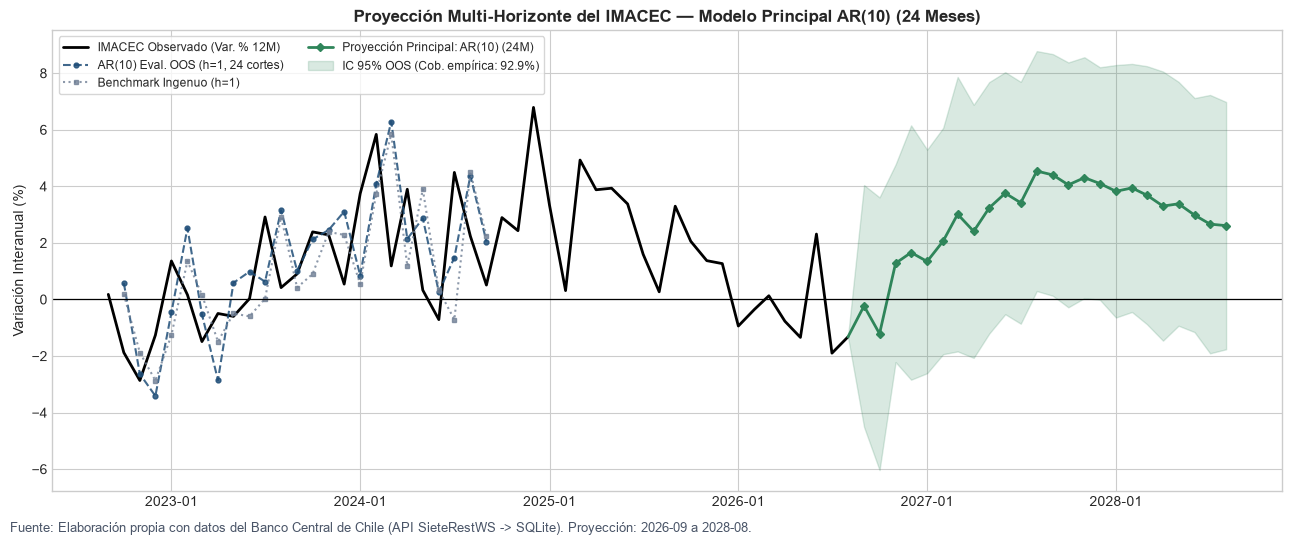

In [14]:
# 1. Preparar ventana reciente (últimos 48 meses observados) para contexto visual
fig, ax = plt.subplots(figsize=(13, 5.4))
y_reciente = y_imacec.iloc[-48:]

# 1.1 Anclar el inicio de la proyección y las bandas al último dato observado (h=0)
fecha_ancla = pd.DatetimeIndex([y_reciente.index[-1]])
valor_ancla = float(y_reciente.iloc[-1])

fechas_proy_plot = fecha_ancla.append(pd.DatetimeIndex(fechas_futuras))
fc_media_plot = np.concatenate([[valor_ancla], np.asarray(fc_media_vals)])
ic_inf_plot = np.concatenate([[valor_ancla], np.asarray(fc_media_vals) - 1.96 * np.asarray(sigma_oos_h)])
ic_sup_plot = np.concatenate([[valor_ancla], np.asarray(fc_media_vals) + 1.96 * np.asarray(sigma_oos_h)])

# 2. Graficar serie observada, evaluación OOS a 1 paso y abanico de proyección a 24 meses
ax.plot(y_reciente.index, y_reciente, color="black", lw=2.0, label="IMACEC Observado (Var. % 12M)")
ax.plot(
    fechas_h1_oos,
    preds_h1_oos,
    "--o",
    color="#1f4e78",
    ms=3.5,
    alpha=0.85,
    label=f"AR({p_optimo_ar}) Eval. OOS (h=1, {N_CORTES} cortes)",
)
ax.plot(
    fechas_h1_oos,
    bench_h1_oos,
    ":s",
    color="#718096",
    ms=3.0,
    alpha=0.8,
    label="Benchmark Ingenuo (h=1)",
)
ax.plot(
    fechas_proy_plot,
    fc_media_plot,
    "-D",
    color="#2f855a",
    ms=4.0,
    lw=2.0,
    markevery=range(1, len(fechas_proy_plot)),
    label=f"Proyección Principal: AR({p_optimo_ar}) (24M)",
)
ax.fill_between(
    fechas_proy_plot,
    ic_inf_plot,
    ic_sup_plot,
    color="#2f855a",
    alpha=0.18,
    label=f"IC 95% OOS (Cob. empírica: {cobertura_emp_pct:.1f}%)",
)

# 3. Línea base de crecimiento nulo, formato de ejes y fuente institucional
ax.axhline(0, color="black", lw=0.9)
ax.set_title(
    f"Proyección Multi-Horizonte del IMACEC — Modelo Principal AR({p_optimo_ar}) (24 Meses)",
    fontsize=12,
    fontweight="bold",
)
ax.set_ylabel("Variación Interanual (%)")
ax.xaxis.set_major_locator(mdates.YearLocator(1))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.legend(loc="upper left", frameon=True, ncol=2, fontsize=8.8)

fig.text(
    0.01,
    0.005,
    "Fuente: Elaboración propia con datos del Banco Central de Chile (API SieteRestWS -> SQLite). Proyección: 2026-09 a 2028-08.",
    fontsize=9,
    color="#4a5568",
)
plt.tight_layout(rect=[0, 0.02, 1, 1])
plt.show()

### Interpretación del Gráfico de Abanico (*Fan Chart*) a 24 Meses (`2026-09` a `2028-08`)

La visualización ejecutiva integra en un único marco temporal la trayectoria observada reciente del IMACEC, la validación histórica fuera de muestra y la proyección dinámica a dos años del modelo principal **`AR(10)`**:

#### 1. Contexto Cíclico Reciente y Punto de Partida (`2022-09` a `2026-08`)
* **Transición desde el repunte de 2024 hacia la debilidad de 2026:** La serie observada (línea negra continua) refleja el ciclo completo posterior al ajuste monetario: tras superar la fase contractiva de fines de 2022 e inicios de 2023, la actividad registró impulsos vigorosos durante 2024 (alcanzando un máximo interanual cercano al `+6.8%` en diciembre de 2024), para luego moderarse de manera sostenida a lo largo de 2025 y cruzar por debajo del umbral de `0%` en 2026, cerrando agosto de 2026 en terreno negativo (`-1.32%`).

#### 2. Contraste Visual de Capacidad Predictiva en Validación (`AR(10)` vs. `Benchmark Ingenuo`)
* **Anticipación de puntos de giro frente al rezago mecánico:** En el tramo de evaluación fuera de muestra (`2022-09` a `2024-08`, $24$ cortes), se aprecia gráficamente la ventaja estructural de **`AR(10)`** (línea azul segmentada) sobre el **`Benchmark Ingenuo`** (línea gris punteada). Mientras el pronóstico ingenuo se limita a desplazar un mes hacia la derecha cada oscilación observada —quedando sistemáticamente atrasado en los cambios de pendiente—, **`AR(10)`** captura la inercia de mediano plazo y acompaña de manera más fiel tanto las fases de recuperación de 2023 como los picos de actividad de 2024.

#### 3. Trayectoria Central Proyectada: Recuperación y Convergencia (`2026-09` a `2028-08`)
* **Salida gradual de la zona contractiva:** La proyección puntual (línea verde con marcadores) indica que el deterioro observado a mediados de 2026 es transitorio: tras registrar tasas levemente negativas en septiembre (`-0.23%`) y octubre de 2026 (`-1.21%`), la economía cruza nuevamente el eje `0%` en **noviembre de 2026 (`+1.28%`)**.
* **Ciclo expansivo en 2027 y estabilización en 2028:** Durante 2027 se proyecta una aceleración sostenida que culmina en **agosto de 2027 (`+4.54%`)**, seguida de una moderación ordenada a lo largo de 2028 hasta converger asintóticamente al crecimiento tendencial de largo plazo de la economía chilena (**`+2.61%` en agosto de 2028**).

#### 4. Lectura del Abanico de Incertidumbre (`IC 95% OOS` con Cobertura Empírica del `92.9%`)
* **Amplitud acotada y estacionaria:** El área sombreada en verde —calibrada directamente sobre la distribución empírica de errores fuera de muestra y validada con una cobertura efectiva del **92.9%**— mantiene una amplitud estable a lo largo de los 24 meses (sin la divergencia explosiva propia de procesos con raíz unitaria).
* **Balance de riesgos por subperíodo:** Hacia el cierre de 2026, el intervalo inferior admite escenarios de contracción más pronunciada (hasta `-6.03%` en octubre de 2026); en contraste, durante el segundo semestre de 2027 prácticamente la totalidad de la masa de probabilidad se sitúa en terreno expansivo por encima del eje `0%` (con un techo superior cercano a `+8.8%`), antes de estabilizarse en un rango simétrico en torno al crecimiento de equilibrio en 2028 (`[-1.76%, +6.98%]`).

## 8. Conclusiones Metodológicas y Reproducibilidad del Entregable Visual

### 8.1 Síntesis Empírica y Respuesta a la Pregunta de Investigación
La evaluación sistemática fuera de muestra (*Out-of-Sample Horse Race*) ejecutada sobre 48 meses (`2022-09` a `2026-08`) demuestra que **la incorporación de indicadores sectoriales, externos, laborales, monetarios y de expectativas aporta ganancias significativas de precisión en el corto plazo ($h = 1$), mientras que los procesos autorregresivos univariados dominan en horizontes de mediano plazo ($12\text{M}$ a $24\text{M}$)**:

1. **Superioridad de la regularización lineal en el monitoreo táctico ($h = 1$, Esquema A):** Bajo reestimación mensual con ventana expansiva, **`Ridge (Pipeline + TimeSeriesSplit)`** alcanza el menor error cuadrático de toda la competencia ($\text{RMSE} = 2.081\text{ pp}$), superando en un **$18.7\%$ al Benchmark Ingenuo** ($R^2_{\text{OOS}} = 0.187$), en un **$20.1\%$ a la Media Histórica Expansiva** ($R^2_{\text{OOS}} = 0.201$) y en un **$31.3\%$ al Benchmark Cero** ($R^2_{\text{OOS}} = 0.313$). La contracción $L_2$ resulta indispensable para extraer la señal anticipatoria de los subsectores internos (*Impuestos, Servicios, Comercio*), las importaciones de consumo y el mercado laboral sin sufrir sobreajuste ante la multicolinealidad de los 46 predictores. Complementariamente, **`SARIMA(2,0,1)(1,0,0,12)`** registra el menor error absoluto medio ($\text{MAE} = 1.668\text{ pp}$), confirmando la relevancia de capturar tanto la dinámica cíclica como los remanentes estacionales.
2. **Ineficacia de particiones no lineales en muestras macroeconómicas acotadas:** Tanto **`Random Forest`** ($\text{RMSE} = 2.488\text{ pp}$) como **`CART`** ($\text{RMSE} = 3.100\text{ pp}$) obtienen valores de $R^2_{\text{OOS}}$ negativos frente a los *benchmarks* lineales. En series macroeconómicas mensuales de tamaño finito ($N = 102$ a $149$) y alta dimensionalidad, los árboles de decisión introducen alta varianza y carecen de capacidad de extrapolación suave ante cambios de régimen.
3. **Robustez estructural de `AR(10)` en horizontes anuales y multi-horizonte (Esquema B):** Al proyectar bloques completos de 12 meses sin actualización mensual de los regresores exógenos, **`AR(10)`** (seleccionado por AIC en entrenamiento, $\text{AIC} = 467.978$) se consolida como el modelo ganador en todas las métricas ($\text{RMSE} = 1.948\text{ pp}$, $\text{MAE} = 1.555\text{ pp}$, $R^2_{\text{OOS}} = 0.076$ frente al Ingenuo y $0.328$ frente a la Media Histórica). Al operar como un sistema cerrado que no requiere proyectar 16 variables exógenas simultáneamente, evita la acumulación de errores de especificación y alcanza una ventaja creciente frente al *Benchmark Ingenuo* ($R^2_{\text{OOS}} = 0.402$ a 12 meses y $0.612$ a 24 meses).

---

### 8.2 Implicancias Macroeconómicas de la Proyección a 24 Meses (`2026-09` a `2028-08`)
A partir del retroceso interanual observado en agosto de 2026 (`-1.32%`), la proyección dinámica del modelo principal **`AR(10)`** —respaldada por intervalos de confianza al 95% calibrados empíricamente con una **cobertura efectiva del $92.9\%$**— sugiere una trayectoria de recuperación ordenada en tres etapas:

* **Inflexión cíclica hacia fines de 2026:** Tras registrar variaciones levemente negativas en septiembre (`-0.23%`) y octubre de 2026 (`-1.21%`), la actividad económica retoma tasas de expansión positivas a partir de **noviembre de 2026 (`+1.28%`)** y **diciembre de 2026 (`+1.66%`)**.
* **Aceleración durante 2027:** Impulsado por la reversión cíclica y bases de comparación favorables, el crecimiento interanual alcanza un máximo proyectado de **`+4.54%` en agosto de 2027 ($h = 12$)**, manteniéndose sobre el `4.0%` hasta el cierre de ese año, con el límite inferior del intervalo al 95% ubicado en terreno positivo (`+0.30%` en agosto y `+0.13%` en septiembre de 2027).
* **Convergencia al crecimiento tendencial en 2028:** Durante los primeros ocho meses de 2028, la expansión se modera suavemente hasta converger a **`+2.61%` en agosto de 2028 ($h = 24$)**, coincidiendo exactamente con el promedio histórico interanual del IMACEC observado entre 2011 y 2026 (`2.61%`) y verificando la estacionariedad en covarianza del proceso estimado.

---

### 8.3 Limitaciones Metodológicas y Líneas de Extensión
* **Quiebres estructurales y heterocedasticidad pandémica:** La contracción abrupta de 2020 (`-15%`) y el rebote de 2021 (`+20%`) introducen volatilidad extrema en la ventana de entrenamiento, afectando la potencia de los contrastes de raíz unitaria en muestras finitas y explicando la ligera ventaja de la *Media Histórica Expansiva* en horizontes intermedios ($h = 12\text{M}$ y $18\text{M}$).
* **Arquitectura híbrida y combinación de pronósticos:** Como extensión natural para uso institucional, se recomienda implementar un esquema encadenado que utilice **`Ridge`** para el *nowcast* táctico del primer mes ($h = 1$) y **`AR(10)`** para la trayectoria de mediano plazo ($h = 2 \dots 24$), así como explorar combinaciones lineales (*forecast combination*) entre `AR(10)` y la media histórica a partir del segundo año de proyección.
* **Modelos estructurales y de frecuencia mixta:** Futuras iteraciones pueden incorporar modelos **VAR Bayesianos (BVAR)** con *priors* de Minnesota para proyectar conjuntamente la TPM, el tipo de cambio y el IMACEC, o esquemas **MIDAS** (*Mixed-Data Sampling*) que integren indicadores semanales o diarios de alta frecuencia.

---

### 8.4 Estándares de Reproducibilidad e Ingeniería del Entregable
El flujo completo de extracción, almacenamiento, modelación econométrica y visualización fue diseñado bajo criterios estrictos de reproducibilidad científica y auditabilidad:

1. **Persistencia local y trazabilidad de datos:** Las 17 series oficiales extraídas desde la API *SieteRestWS* del Banco Central de Chile se almacenan de forma estructurada en una base relacional **SQLite** (`data/bcch_macro.db`), desacoplando la ingesta de datos del análisis econométrico y asegurando que cualquier ejecución posterior opere sobre exactamente la misma instantánea histórica.
2. **Prevención integral de fuga de datos (*Zero Data Leakage*):** Todas las decisiones de especificación —incluyendo las pruebas ADF, la selección del orden óptimo $p^* = 10$ por AIC, la estandarización (`StandardScaler`) y la búsqueda de hiperparámetros mediante `TimeSeriesSplit(n_splits=5)`— se ejecutaron estrictamente dentro de la muestra de entrenamiento (`hasta 2022-08-01`), verificando además **cero cortes en los bordes de grilla** (`Elastic Net = 0`, `Ridge = 0`) a lo largo de los 48 pasos del *backtesting*.
3. **Modularidad, seguridad y generación determinista de artefactos:** La lógica de negocio reside en módulos reutilizables (`src/config.py`, `src/bcch_client.py`, `src/database.py`, `src/transforms.py`), gestiona credenciales de forma aislada mediante variables de entorno (`.env`) y exporta automáticamente tanto las tablas de métricas consolidadas como los gráficos ejecutivos de coyuntura y proyección (*Fan Chart*) en alta resolución.